In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/shyamjadoun/cardiovascular-disease/cardio_train.csv


# **HEART DISEASE ANALYSIS** 


In this project, we will analyze [Cardiovascular Disease dataset] [CVD] (https://www.kaggle.com/sulianova/cardiovascular-disease-dataset) to find which variables are related to the disease. Then we will use different machine learning models to predict whether the patient has  cardiovascular disease or not. <br>The dataset contains information about patients doing cardiovascular disease examination.<br><br>
**Data features:**
   - Age | Objective Feature | age | int (years)<br>
   - Height | Objective Feature | height | int (cm) |<br>
   - Weight | Objective Feature | weight | float (kg) |<br>
   - BMI | Objective Feature | bmi | int |<br>
   - Gender | Objective Feature | gender | categorical code |<br>
   - Systolic blood pressure | Examination Feature | ap_hi | int |<br>
   - Diastolic blood pressure | Examination Feature | ap_lo | int |<br>
   - Cholesterol | Examination Feature | cholesterol | 1: normal, 2: above normal, 3: well above normal |<br>
   - Glucose | Examination Feature | gluc | 1: normal, 2: above normal, 3: well above normal |<br>
   - Smoking | Subjective Feature | smoke | binary |<br>
   - Alcohol | Subjective Feature | alco | binary |<br>
   - Physical Activity | Subjective Feature | active | binary |<br>
   - Presence or absence of cardiovascular disease | Target Variable | cardio | binary |<br>


In [2]:
#loading dataset
import pandas as pd
import numpy as np

#visualisation
import matplotlib.pyplot as plt
import seaborn as sns
# data preprocessing
from sklearn.preprocessing import StandardScaler

# data splitting
from sklearn.model_selection import train_test_split

# data modeling
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_curve
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score

# All Model`s
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import  AdaBoostClassifier
from sklearn.ensemble import  GradientBoostingClassifier


In [3]:
data = pd.read_csv('/kaggle/input/datasets/shyamjadoun/cardiovascular-disease/cardio_train.csv',sep=';')
data

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,99993,19240,2,168,76.0,120,80,1,1,1,0,1,0
69996,99995,22601,1,158,126.0,140,90,2,2,0,0,1,1
69997,99996,19066,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,22431,1,163,72.0,135,80,1,2,0,0,0,1


## Data Modification

In [4]:
data['weight'] = data['weight'].astype(int)


In [5]:
data['BMI'] = data['weight']/((data['height']/100)**2)
data['BMI'] = data['BMI'].astype(int)

data['Age'] = data['age']/365
data['Age'] = data['Age'].astype(int)

In [6]:
#Body Mass Index = BMI
#Systolic blood pressure = ap_hi
#Diastolic blood pressure = ap_lo
data['Systolic Blood Pressure'] = data['ap_hi'].astype(int)
data['Diastolic Blood Pressure'] = data['ap_lo'].astype(int)

In [7]:
data.drop(['id', 'age', 'gender', 'cholesterol', 'gluc', 'smoke', 'alco','active','height','weight', 'ap_hi','ap_lo' ], axis=1, inplace=True)
data

,cardio,BMI,Age,Systolic Blood Pressure,Diastolic Blood Pressure
0,0,21,50,110,80
1,1,34,55,140,90
2,1,23,51,130,70
3,1,28,48,150,100
4,0,23,47,100,60
...,...,...,...,...,...
69995,0,26,52,120,80
69996,1,50,61,140,90
69997,1,31,52,180,90
69998,1,27,61,135,80


In [8]:
data.describe()

,cardio,BMI,Age,Systolic Blood Pressure,Diastolic Blood Pressure
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,0.499700,27.064286,52.840671,128.817286,96.630414
std,0.500003,6.100707,6.766774,154.011419,188.472530
min,0.000000,3.000000,29.000000,-150.000000,-70.000000
25%,0.000000,23.000000,48.000000,120.000000,80.000000
50%,0.000000,26.000000,53.000000,120.000000,80.000000
75%,1.000000,30.000000,58.000000,140.000000,90.000000
max,1.000000,298.000000,64.000000,16020.000000,11000.000000


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   cardio                    70000 non-null  int64
 1   BMI                       70000 non-null  int64
 2   Age                       70000 non-null  int64
 3   Systolic Blood Pressure   70000 non-null  int64
 4   Diastolic Blood Pressure  70000 non-null  int64
dtypes: int64(5)
memory usage: 2.7 MB


In [10]:
data.cardio.value_counts()

cardio
0    35021
1    34979
Name: count, dtype: int64

### **Missing Value Detection**


In [11]:
print("{} rows are same".format(data.duplicated().sum()))

48442 rows are same


In [12]:
data.drop_duplicates(inplace= True)
print("{} rows are same".format(data.duplicated().sum()))

0 rows are same


Text(0.5, 1.0, 'Visualization of outliers')

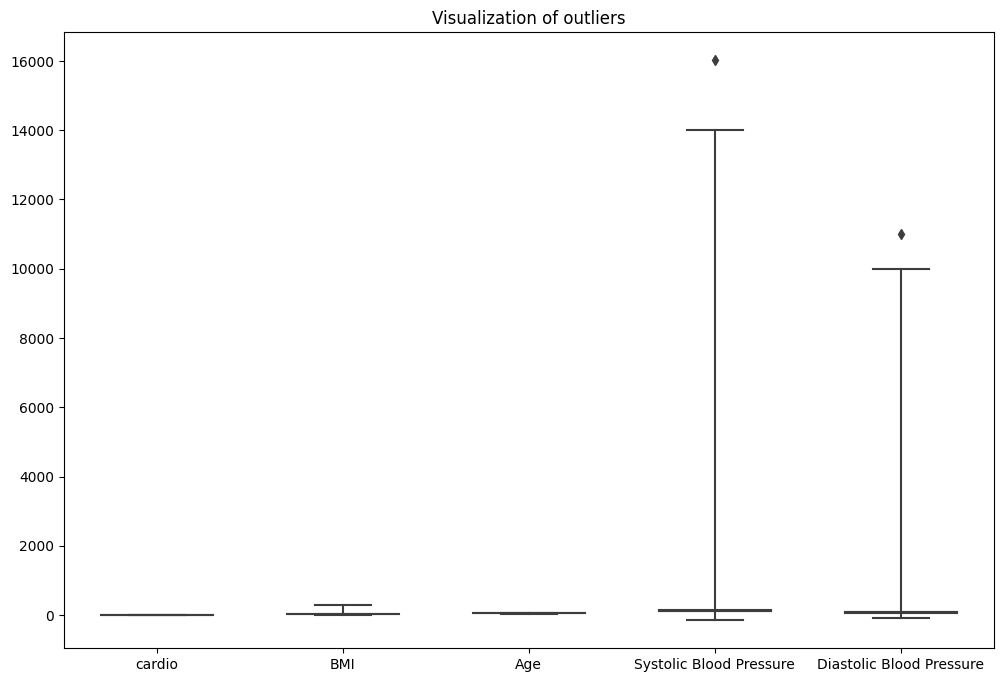

In [13]:
# BoxPlot after removing the outliers.
fig, ax = plt.subplots(figsize = (12,8))
sns.boxplot(data = data, width = .6, whis=500, ax = ax, fliersize = 5)
plt.title("Visualization of outliers")

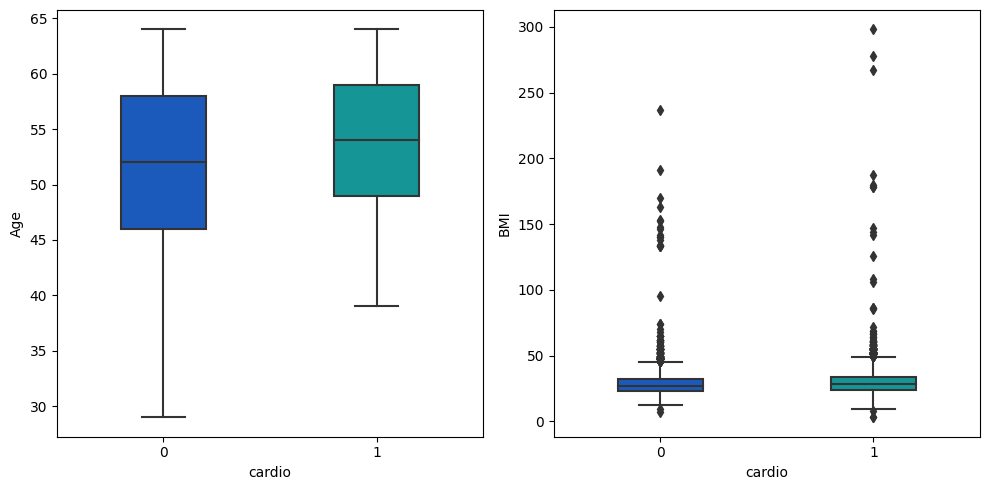

In [14]:
fig,ax = plt.subplots(1,2,figsize=(10,5))
sns.boxplot(y=data['Age'],x=data['cardio'],ax=ax[0], width = .4, palette='winter')
sns.boxplot(y=data['BMI'],x=data['cardio'],ax=ax[1], width = .4, palette='winter')
plt.tight_layout()

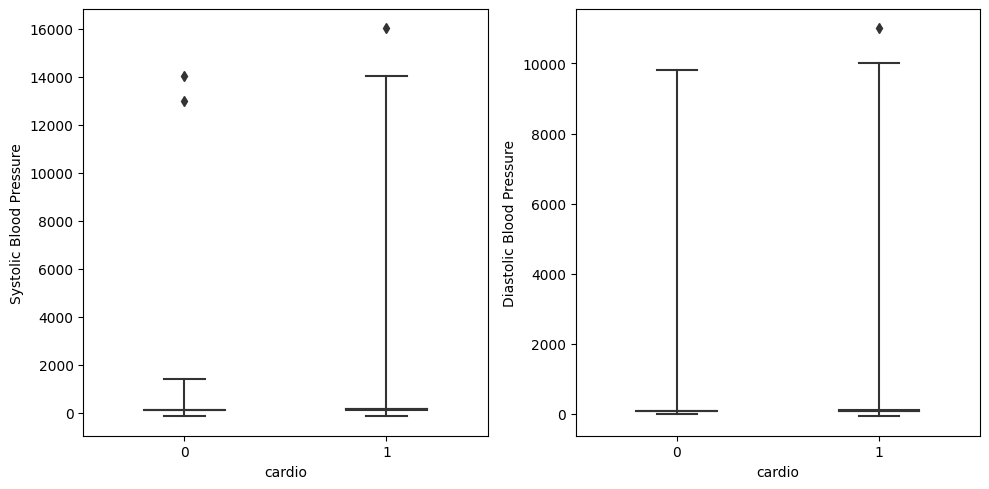

In [15]:
fig,ax = plt.subplots(1,2,figsize=(10,5))
sns.boxplot(y=data['Systolic Blood Pressure'],x=data['cardio'],ax=ax[0],whis=500, width = .4, palette='winter')
sns.boxplot(y=data['Diastolic Blood Pressure'],x=data['cardio'],ax=ax[1],whis=500, width = .4, palette='winter')
plt.tight_layout()

In [16]:
df_c0 = data[data['cardio'] == 0]
lista = ['Systolic Blood Pressure', 'Diastolic Blood Pressure', 'BMI','Age']
df_quartil = pd.DataFrame(index=['Q minimo', 'Q maximo'])

for e in lista:
    Q1 = df_c0[e].quantile(0.25)
    Q3 = df_c0[e].quantile(0.75)
    IQR = Q3 - Q1
    
    minimo = Q1 - (1.5 * IQR)
    maximo = Q3+ (1.5 * IQR)
    
    df_quartil[e]= [minimo, maximo]
    
df_quartil

,Systolic Blood Pressure,Diastolic Blood Pressure,BMI,Age
Q minimo,80.0,40.0,9.5,28.0
Q maximo,160.0,120.0,45.5,76.0


opt/conda/lib/python3.7/site-packages/pandas/core/frame.py:4913: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  errors=errors,

In [17]:
outlier_c0 = df_c0[(df_c0['Diastolic Blood Pressure']>90)|(df_c0['Diastolic Blood Pressure']<60)|(df_c0['Systolic Blood Pressure']>130)|(df_c0['Systolic Blood Pressure']<100)|(df_c0['Age']>64)|(df_c0['Age']<39)| (df_c0['BMI']>24.9)|(df_c0['BMI']<18.5)].index
df_c0.drop(outlier_c0, inplace=True)

/tmp/ipykernel_17/1918312985.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_c0.drop(outlier_c0, inplace=True)


In [18]:
df_c0.describe()

,cardio,BMI,Age,Systolic Blood Pressure,Diastolic Blood Pressure
count,2059.0,2059.000000,2059.000000,2059.000000,2059.000000
mean,0.0,21.890724,51.016513,115.196697,75.021370
std,0.0,1.623804,7.209466,10.015764,9.367589
min,0.0,19.000000,39.000000,100.000000,60.000000
25%,0.0,21.000000,45.000000,110.000000,70.000000
50%,0.0,22.000000,51.000000,120.000000,78.000000
75%,0.0,23.000000,57.000000,120.000000,80.000000
max,0.0,24.000000,64.000000,130.000000,90.000000


In [19]:
df_c1 = data[data['cardio'] == 1]

In [20]:
lista = ['Systolic Blood Pressure', 'Diastolic Blood Pressure', 'BMI','Age']
df_quartil = pd.DataFrame(index=['Q minimo', 'Q maximo'])

for e in lista:
    Q1 = df_c1[e].quantile(0.25)
    Q3 = df_c1[e].quantile(0.75)
    IQR = Q3 - Q1
    
    minimo = Q1 - (1.5 * IQR)
    maximo = Q3+ (1.5 * IQR)
    
    df_quartil[e]= [minimo, maximo]
    
df_quartil


,Systolic Blood Pressure,Diastolic Blood Pressure,BMI,Age
Q minimo,75.0,50.0,9.0,34.0
Q maximo,195.0,130.0,49.0,74.0


In [21]:
outlier_c1 = df_c1[(df_c1['Diastolic Blood Pressure']>105)|(df_c1['Diastolic Blood Pressure']<70)|(df_c1['Systolic Blood Pressure']>170)|(df_c1['Systolic Blood Pressure']<90)|(df_c0['Age']>64)|(df_c0['Age']<39)|(df_c1['BMI']>40)|(df_c1['BMI']<16)].index
df_c1.drop(outlier_c1, inplace=True)
df_c1.describe()

/tmp/ipykernel_17/93697928.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  outlier_c1 = df_c1[(df_c1['Diastolic Blood Pressure']>105)|(df_c1['Diastolic Blood Pressure']<70)|(df_c1['Systolic Blood Pressure']>170)|(df_c1['Systolic Blood Pressure']<90)|(df_c0['Age']>64)|(df_c0['Age']<39)|(df_c1['BMI']>40)|(df_c1['BMI']<16)].index
/tmp/ipykernel_17/93697928.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_c1.drop(outlier_c1, inplace=True)


,cardio,BMI,Age,Systolic Blood Pressure,Diastolic Blood Pressure
count,8854.0,8854.000000,8854.000000,8854.000000,8854.000000
mean,1.0,28.406144,53.294217,136.240456,85.095776
std,0.0,5.564929,6.974422,17.693396,9.644387
min,1.0,16.000000,39.000000,90.000000,70.000000
25%,1.0,24.000000,48.000000,120.000000,80.000000
50%,1.0,28.000000,54.000000,140.000000,85.000000
75%,1.0,33.000000,59.000000,150.000000,90.000000
max,1.0,40.000000,64.000000,170.000000,105.000000


<Axes: xlabel='colunas', ylabel='valores'>

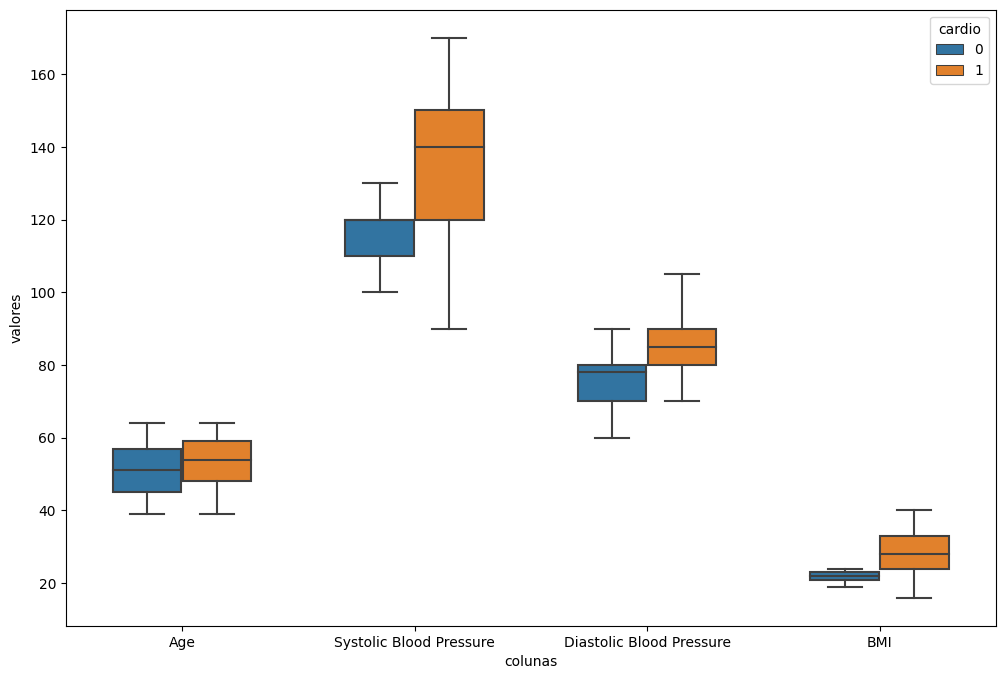

In [22]:
data = pd.concat([df_c0, df_c1])
df = pd.melt(data,id_vars='cardio', value_vars=['Age', 'Systolic Blood Pressure', 'Diastolic Blood Pressure', 'BMI'], var_name='colunas', value_name='valores', col_level=None)
plt.figure(figsize=(12,8))
sns.boxplot(x='colunas', y='valores',whis=1.5, width = .6, hue='cardio', data=df)

<Axes: xlabel='colunas', ylabel='valores'>

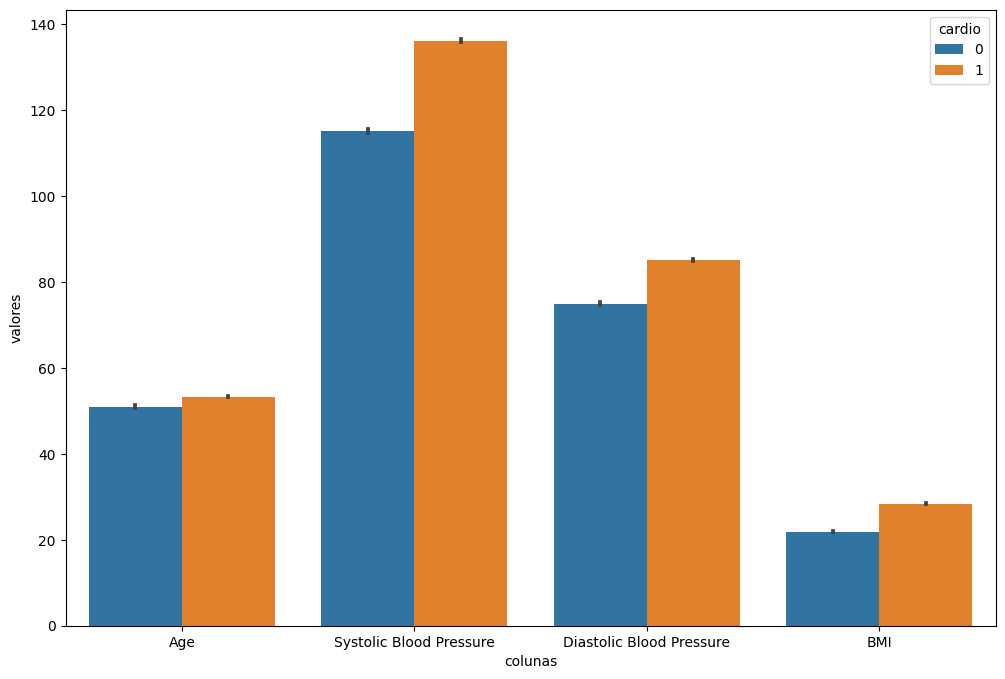

In [23]:
plt.figure(figsize=(12,8))
sns.barplot(x='colunas', y='valores', hue='cardio',data=df)

### **Missing Value Detection**

In [24]:
data.isnull().sum()

cardio                      0
BMI                         0
Age                         0
Systolic Blood Pressure     0
Diastolic Blood Pressure    0
dtype: int64

In [25]:
pd.set_option("display.float", "{:.2f}".format)
data.describe()


,cardio,BMI,Age,Systolic Blood Pressure,Diastolic Blood Pressure
count,10913.00,10913.00,10913.00,10913.00,10913.00
mean,0.81,27.18,52.86,132.27,83.19
std,0.39,5.67,7.08,18.46,10.37
min,0.00,16.00,39.00,90.00,60.00
25%,1.00,23.00,47.00,120.00,79.00
50%,1.00,26.00,53.00,130.00,80.00
75%,1.00,31.00,59.00,150.00,90.00
max,1.00,40.00,64.00,170.00,105.00


# Visualization 


In [26]:
data.cardio.value_counts()

cardio
1    8854
0    2059
Name: count, dtype: int64

0 = No Cardio 1 = Cardio


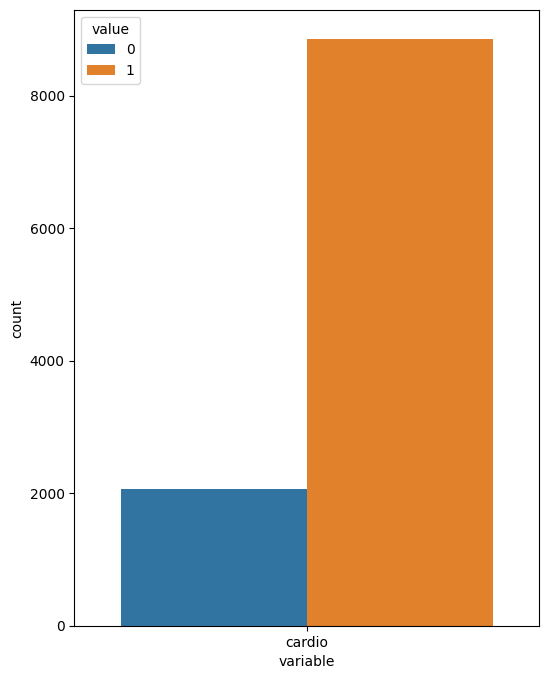

In [27]:
plt.figure(figsize=(6,8))
dataframe_categorical = data.loc[:,['cardio']]
sns.countplot(x="variable", hue="value",data= pd.melt(dataframe_categorical));

print ("0 = No Cardio", "1 = Cardio" )


0 = No Cardio 1 = Cardio


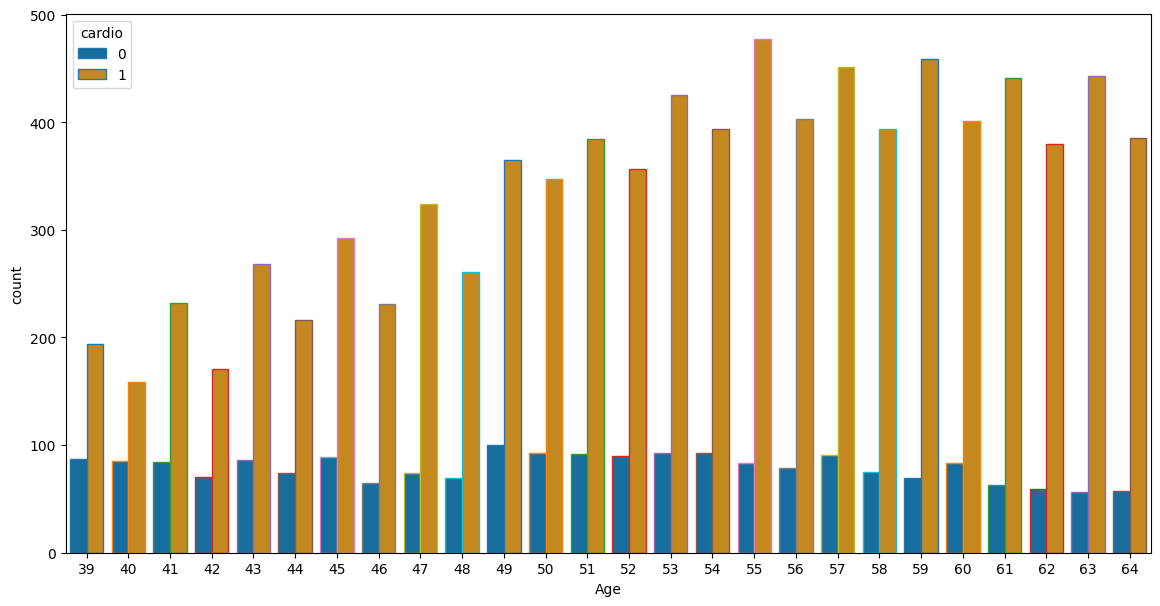

In [28]:
plt.figure(figsize = (14,7))
sns.countplot(x='Age', hue = 'cardio', data = data, palette = 'colorblind', edgecolor = sns.color_palette(as_cmap='RdGy_r', n_colors=5));
print ("0 = No Cardio", "1 = Cardio" )

In [29]:
categorical_val = []
continous_val = []
for column in data.columns:
    if len(data[column].unique()) <= 10:
        categorical_val.append(column)
    else:
        continous_val.append(column)

In [30]:
continous_val

['BMI', 'Age', 'Systolic Blood Pressure', 'Diastolic Blood Pressure']

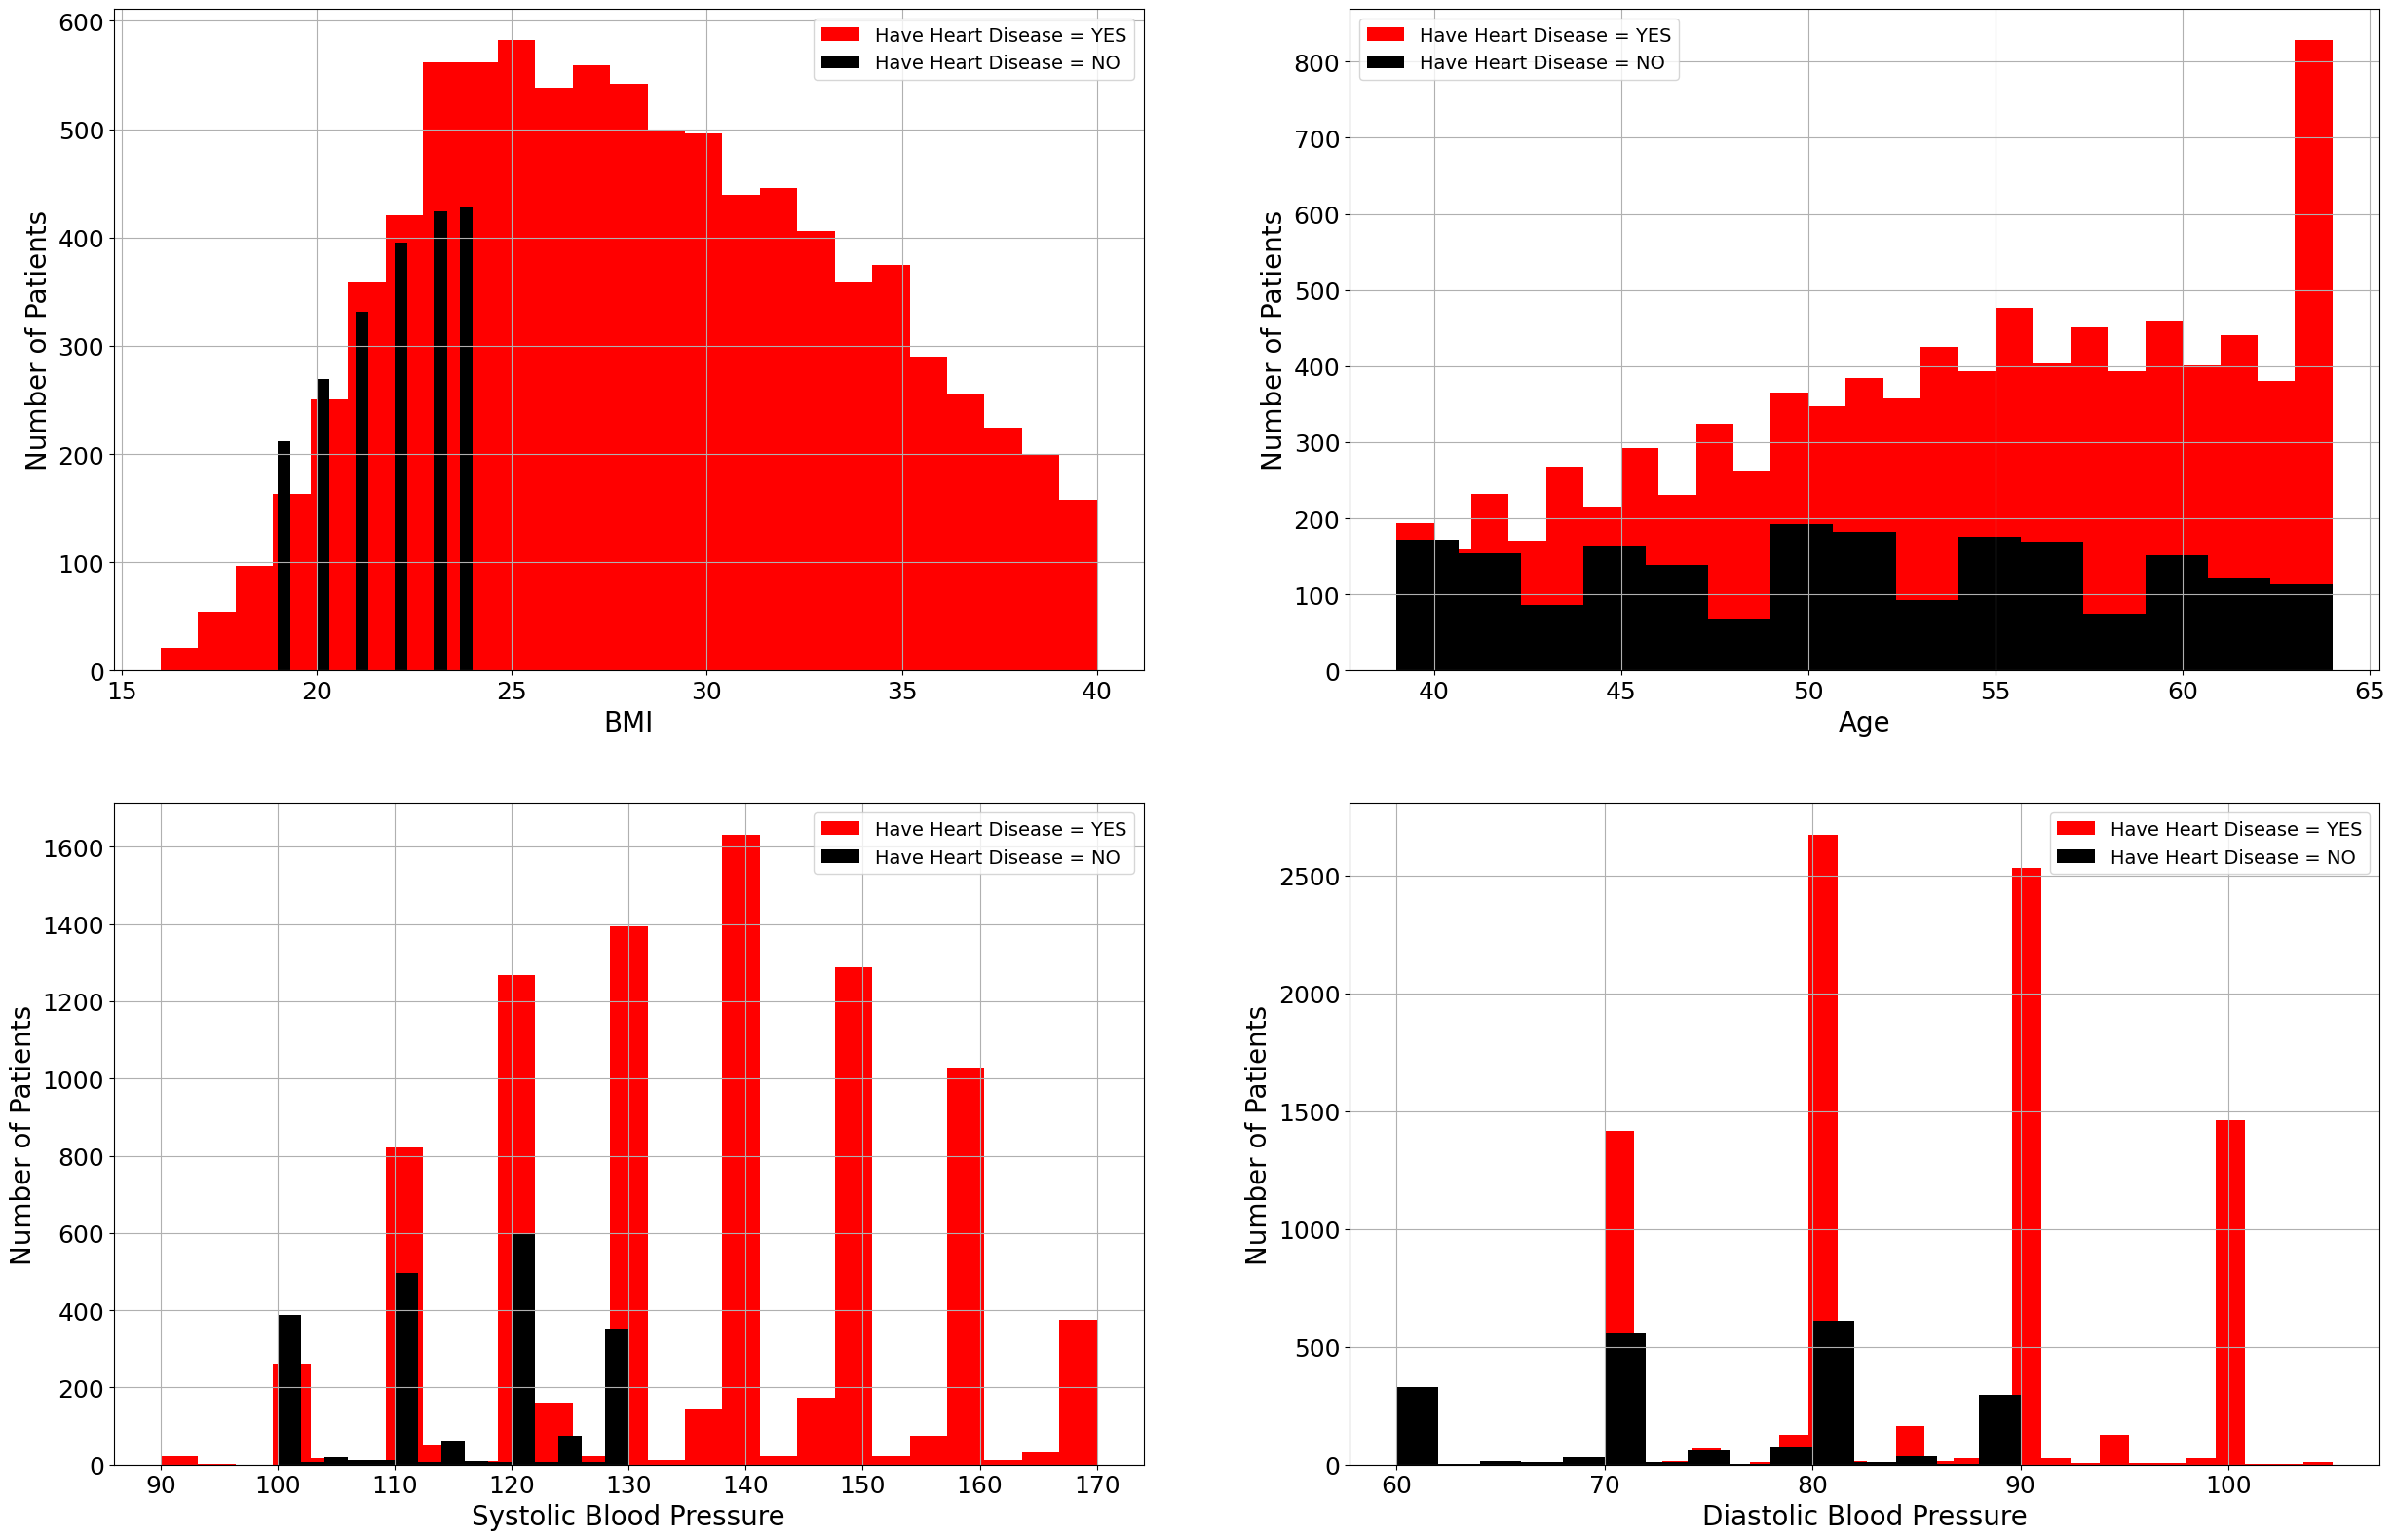

In [31]:
plt.figure(figsize=(30, 30))

for i, column in enumerate(continous_val,1):
    plt.subplot(3, 2, i)
    data[data["cardio"] == 1][column].hist(bins=25, color='Red', label='Have Heart Disease = YES', alpha=1)
    data[data["cardio"] == 0][column].hist(bins=15, color='Black', label='Have Heart Disease = NO', alpha=1)
    plt.legend(fontsize=14)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.xlabel(column,fontsize=20)
    plt.ylabel("Number of Patients" ,fontsize=20)

In [32]:
data.corr()

,cardio,BMI,Age,Systolic Blood Pressure,Diastolic Blood Pressure
cardio,1.00,0.45,0.13,0.45,0.38
BMI,0.45,1.00,0.08,0.29,0.26
Age,0.13,0.08,1.00,0.11,0.05
Systolic Blood Pressure,0.45,0.29,0.11,1.00,0.60
Diastolic Blood Pressure,0.38,0.26,0.05,0.60,1.00


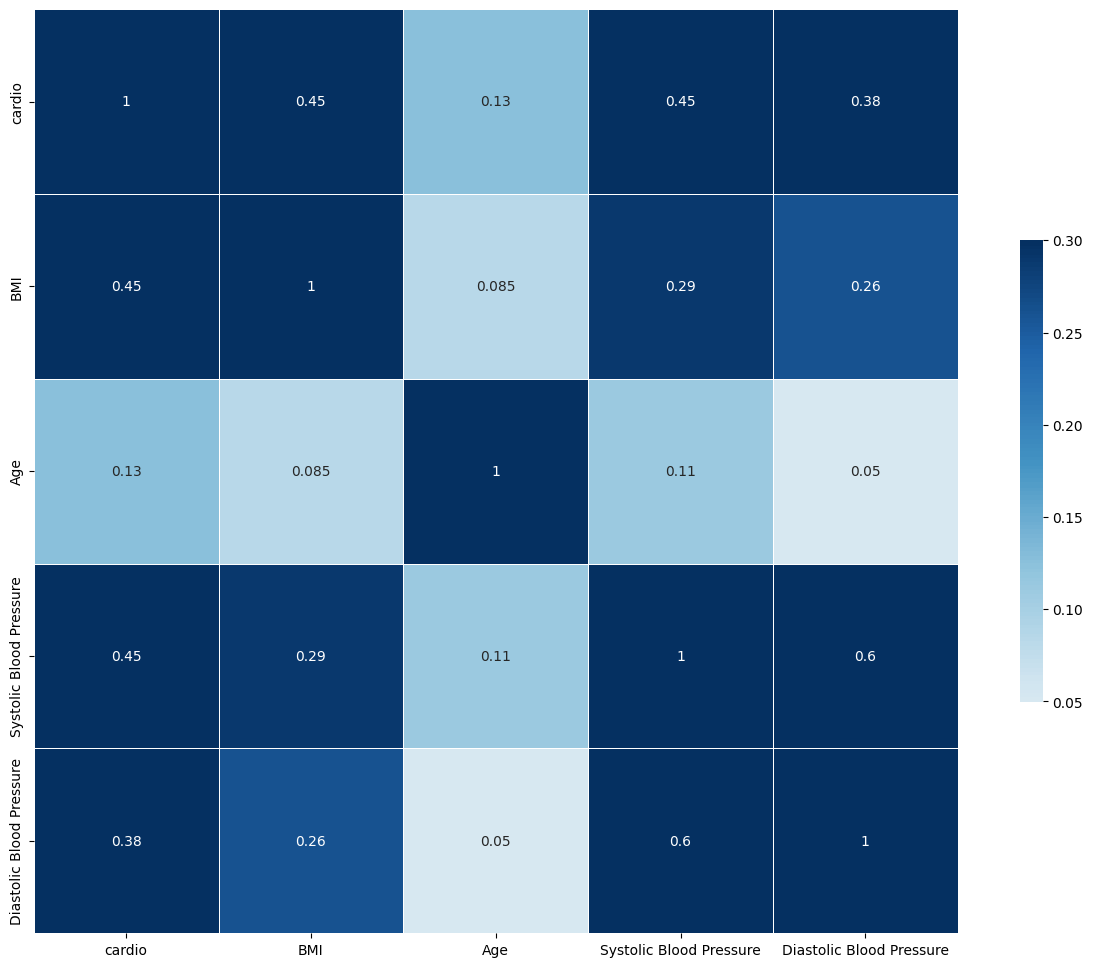

In [33]:
# Multivariate Analysis & Correlation Detection
import seaborn as sb
correl = data.corr()
cmap = sb.diverging_palette(220, 10, as_cmap = True)

fig, ax = plt.subplots(figsize = (16, 12))
sb.heatmap(correl, cmap ='RdBu', vmax = 0.3, center = 0,annot = True, square = True, linewidths = 0.5, cbar_kws = {"shrink": .5});

- `fbs` and `chol` are the lowest correlated with the target variable.
- All other variables have a significant correlation with the target variable.


# Data Processing

After exploring the dataset, I observed that I need to convert some categorical variables into dummy variables and scale all the values before training the Machine Learning models.
First, I'll use the `get_dummies` method to create dummy columns for categorical variables.

In [34]:
categorical_val.remove('cardio')
dataset = pd.get_dummies(data, columns = categorical_val)

In [35]:
dataset

,cardio,BMI,Age,Systolic Blood Pressure,Diastolic Blood Pressure
0,0,21,50,110,80
4,0,23,47,100,60
11,0,20,51,120,80
12,0,22,40,120,80
17,0,20,45,110,70
...,...,...,...,...,...
69933,1,26,55,110,80
69934,1,34,43,120,90
69947,1,38,63,110,80
69949,1,24,60,167,85


## **Probability and Statistics** 

In [36]:
def BPCategorize(x,y):
    if x<=120 and y<=80:
        return 'normal'
    elif x<=129 and y<=80:
        return 'elevated'
    elif x<=139 or y<=89:
        return 'high 1'
    elif x<=140 or y<=90:
        return "high 2"
    else:
        return None
    
data.insert(1,"bp_cat", data.apply(lambda row: BPCategorize(row['Systolic Blood Pressure'], row['Diastolic Blood Pressure']), axis=1))
data['bp_cat'].value_counts()


bp_cat
high 1      4125
normal      3442
high 2      2016
elevated     203
Name: count, dtype: int64

**Probability that a person has cardio diseases given that he is 50 or older**

In [37]:
# Probability that a person has cardio diseases given that he is 39 or older

data_age_50 = data.query('Age >=39')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

81.13

In [38]:
# Probability that a person has cardio diseases given that he is 49 or older

data_age_50 = data.query('Age >=40')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

81.45

In [39]:
# Probability that a person has cardio diseases given that he is 41 or older

data_age_50 = data.query('Age >=41')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

81.83

In [40]:
# Probability that a person has cardio diseases given that he is 42 or older

data_age_50 = data.query('Age >=42')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

82.1

In [41]:
# Probability that a person has cardio diseases given that he is 43 or older

data_age_50 = data.query('Age >=43')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

82.37

In [42]:
# Probability that a person has cardio diseases given that he is 44 or older

data_age_50 = data.query('Age >=44')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

82.62

In [43]:
# Probability that a person has cardio diseases given that he is 45 or older

data_age_50 = data.query('Age >=45')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

82.88

In [44]:
# Probability that a person has cardio diseases given that he is 46 or older

data_age_50 = data.query('Age >=46')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

83.15

In [45]:
# Probability that a person has cardio diseases given that he is 47 or older

data_age_50 = data.query('Age >=47')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

83.33

In [46]:
# Probability that a person has cardio diseases given that he is 48 or older

data_age_50 = data.query('Age >=48')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

83.42

In [47]:
# Probability that a person has cardio diseases given that he is 49 or older

data_age_50 = data.query('Age >=49')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

83.6

In [48]:
# Probability that a person has cardio diseases given that he is 50 or older

data_age_50 = data.query('Age >=50')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

83.93

In [49]:
# Probability that a person has cardio diseases given that he is 51 or older

data_age_50 = data.query('Age >=51')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

84.25

In [50]:
# Probability that a person has cardio diseases given that he is 52 or older

data_age_50 = data.query('Age >=52')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

84.52

In [51]:
# Probability that a person has cardio diseases given that he is 53 or older

data_age_50 = data.query('Age >=53')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

84.87

In [52]:
# Probability that a person has cardio diseases given that he is 54 or older

data_age_50 = data.query('Age >=54')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

85.14

In [53]:
# Probability that a person has cardio diseases given that he is 55 or older

data_age_50 = data.query('Age >=55')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

85.55

In [54]:
# Probability that a person has cardio diseases given that he is 56 or older

data_age_50 = data.query('Age >=56')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

85.6

In [55]:
# Probability that a person has cardio diseases given that he is 57 or older

data_age_50 = data.query('Age >=57')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

85.85

In [56]:
# Probability that a person has cardio diseases given that he is 58 or older

data_age_50 = data.query('Age >=58')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

86.27

In [57]:
# Probability that a person has cardio diseases given that he is 59 or older

data_age_50 = data.query('Age >=59')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

86.64

In [58]:
# Probability that a person has cardio diseases given that he is 60 or older

data_age_50 = data.query('Age >=60')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

86.57

In [59]:
# Probability that a person has cardio diseases given that he is 61 or older

data_age_50 = data.query('Age >=61')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

87.53

In [60]:
# Probability that a person has cardio diseases given that he is 62 or older

data_age_50 = data.query('Age >=62')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

87.54

In [61]:
# Probability that a person has cardio diseases given that he is 63 or older

data_age_50 = data.query('Age >=63')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

87.99

In [62]:
# Probability that a person has cardio diseases given that he is 64 or older

data_age_50 = data.query('Age >=64')
data_agy_50_cardio = data_age_50.query('cardio==1')
round(data_agy_50_cardio.shape[0]*100/data_age_50.shape[0],2)

87.1

**Probability that a person has cardio diseases given that he has body mass index **


In [63]:
# Probability that a person has cardio diseases given that he has body mass index greater than 15

data_BMI23 = data.query('BMI>=15')
data_BMI23_cardio = data_BMI23.query('cardio ==1')
round(data_BMI23_cardio.shape[0]*100/data_BMI23.shape[0],2)

81.13

In [64]:
# Probability that a person has cardio diseases given that he has body mass index greater than 16

data_BMI23 = data.query('BMI>=16')
data_BMI23_cardio = data_BMI23.query('cardio ==1')
round(data_BMI23_cardio.shape[0]*100/data_BMI23.shape[0],2)

81.13

In [65]:
# Probability that a person has cardio diseases given that he has body mass index greater than 17

data_BMI23 = data.query('BMI>=17')
data_BMI23_cardio = data_BMI23.query('cardio ==1')
round(data_BMI23_cardio.shape[0]*100/data_BMI23.shape[0],2)

81.1

In [66]:
# Probability that a person has cardio diseases given that he has body mass index greater than 18

data_BMI23 = data.query('BMI>=18')
data_BMI23_cardio = data_BMI23.query('cardio ==1')
round(data_BMI23_cardio.shape[0]*100/data_BMI23.shape[0],2)

81.0

In [67]:
# Probability that a person has cardio diseases given that he has body mass index greater than 19

data_BMI23 = data.query('BMI>=19')
data_BMI23_cardio = data_BMI23.query('cardio ==1')
round(data_BMI23_cardio.shape[0]*100/data_BMI23.shape[0],2)

80.83

In [68]:
# Probability that a person has cardio diseases given that he has body mass index greater than 20

data_BMI23 = data.query('BMI>=20')
data_BMI23_cardio = data_BMI23.query('cardio ==1')
round(data_BMI23_cardio.shape[0]*100/data_BMI23.shape[0],2)

82.18

In [69]:
# Probability that a person has cardio diseases given that he has body mass index greater than 21

data_BMI23 = data.query('BMI>=21')
data_BMI23_cardio = data_BMI23.query('cardio ==1')
round(data_BMI23_cardio.shape[0]*100/data_BMI23.shape[0],2)

83.97

In [70]:
# Probability that a person has cardio diseases given that he has body mass index greater than 22

data_BMI23 = data.query('BMI>=22')
data_BMI23_cardio = data_BMI23.query('cardio ==1')
round(data_BMI23_cardio.shape[0]*100/data_BMI23.shape[0],2)

86.38

In [71]:
# Probability that a person has cardio diseases given that he has body mass index greater than 23

data_BMI23 = data.query('BMI>=23')
data_BMI23_cardio = data_BMI23.query('cardio ==1')
round(data_BMI23_cardio.shape[0]*100/data_BMI23.shape[0],2)

89.79

In [72]:
# Probability that a person has cardio diseases given that he has body mass index greater than 24

data_BMI23 = data.query('BMI>=24')
data_BMI23_cardio = data_BMI23.query('cardio ==1')
round(data_BMI23_cardio.shape[0]*100/data_BMI23.shape[0],2)

94.18

In [73]:
# Probability that a person has cardio diseases given that he has body mass index greater than 25

data_BMI23 = data.query('BMI>=25')
data_BMI23_cardio = data_BMI23.query('cardio ==1')
round(data_BMI23_cardio.shape[0]*100/data_BMI23.shape[0],2)

100.0

**Probability that a person has cardio diseases given that the patient has a hypertensive crisis**

In [74]:
# Probability that a person has cardio diseases given that the patient has a hypertensive crisis

data_high3 = data.query("bp_cat == 'normal'")
data_high_cardio = data_high3.query('cardio == 1')
round(data_high_cardio.shape[0]*100/data_high3.shape[0],2)

59.21

In [75]:
# Probability that a person has cardio diseases given that the patient has a hypertensive crisis

data_high3 = data.query("bp_cat == 'elevated'")
data_high_cardio = data_high3.query('cardio == 1')
round(data_high_cardio.shape[0]*100/data_high3.shape[0],2)

62.56

In [76]:
# Probability that a person has cardio diseases given that the patient has a hypertensive crisis

data_high3 = data.query("bp_cat == 'high 1'")
data_high_cardio = data_high3.query('cardio == 1')
round(data_high_cardio.shape[0]*100/data_high3.shape[0],2)

85.96

In [77]:
# Probability that a person has cardio diseases given that the patient has a hypertensive crisis

data_high3 = data.query("bp_cat == 'high 2'")
data_high_cardio = data_high3.query('cardio == 1')
round(data_high_cardio.shape[0]*100/data_high3.shape[0],2)

100.0

In [78]:
print(data.columns)
print(dataset.columns)

Index(['cardio', 'bp_cat', 'BMI', 'Age', 'Systolic Blood Pressure',
       'Diastolic Blood Pressure'],
      dtype='object')
Index(['cardio', 'BMI', 'Age', 'Systolic Blood Pressure',
       'Diastolic Blood Pressure'],
      dtype='object')


# Data Transform into StandardScaler


In [79]:
from sklearn.preprocessing import StandardScaler

s_sc = StandardScaler()
col_to_scale = ['Systolic Blood Pressure', 'Diastolic Blood Pressure', 'BMI', 'Age']
dataset[col_to_scale] = s_sc.fit_transform(dataset[col_to_scale])

In [80]:
dataset

,cardio,BMI,Age,Systolic Blood Pressure,Diastolic Blood Pressure
0,0,-1.09,-0.40,-1.21,-0.31
4,0,-0.74,-0.83,-1.75,-2.24
11,0,-1.27,-0.26,-0.66,-0.31
12,0,-0.91,-1.82,-0.66,-0.31
17,0,-1.27,-1.11,-1.21,-1.27
...,...,...,...,...,...
69933,1,-0.21,0.30,-1.21,-0.31
69934,1,1.20,-1.39,-0.66,0.66
69947,1,1.91,1.43,-1.21,-0.31
69949,1,-0.56,1.01,1.88,0.17


## **Model Prepration**

In [81]:
from sklearn.model_selection import train_test_split

X = dataset.drop("cardio", axis = 1)

y = dataset["cardio"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=100, shuffle=100,)

In [82]:
print('Train set shape is',format(X_train.shape))
print('Test set shape is',format(X_test.shape))


Train set shape is (7639, 4)
Test set shape is (3274, 4)


In [83]:
def print_score(clf, X_train, y_train, X_test, y_test, train=True):
    if train:
        pred = clf.predict(X_train)
        clf_report = pd.DataFrame(classification_report(y_train, pred, output_dict=True))
        print("Train Result:\n================================================")
        print(f"Accuracy Score: {accuracy_score(y_train, pred) * 100:.2f}%")
        print("_______________________________________________")
        print(f"CLASSIFICATION REPORT:\n{clf_report}")
        print("_______________________________________________")
        print(f"Confusion Matrix: \n {confusion_matrix(y_train, pred)}\n")
        
    elif train==False:
        pred = clf.predict(X_test)
        clf_report = pd.DataFrame(classification_report(y_test, pred, output_dict=True))
        print("Test Result:\n================================================")        
        print(f"Accuracy Score: {accuracy_score(y_test, pred) * 100:.2f}%")
        print("_______________________________________________")
        print(f"CLASSIFICATION REPORT:\n{clf_report}")
        print("_______________________________________________")
        print(f"Confusion Matrix: \n {confusion_matrix(y_test, pred)}\n")

## 1. XGBoost Classifer

In [84]:
from xgboost import XGBClassifier

xgb_clf = XGBClassifier()
xgb_clf.fit(X_train, y_train)

print_score(xgb_clf, X_train, y_train, X_test, y_test, train=True)
print_score(xgb_clf, X_train, y_train, X_test, y_test, train=False)

Train Result:
Accuracy Score: 93.36%
_______________________________________________
CLASSIFICATION REPORT:
                0       1  accuracy  macro avg  weighted avg
precision    0.80    0.97      0.93       0.89          0.94
recall       0.85    0.95      0.93       0.90          0.93
f1-score     0.83    0.96      0.93       0.89          0.93
support   1434.00 6205.00      0.93    7639.00       7639.00
_______________________________________________
Confusion Matrix: 
 [[1224  210]
 [ 297 5908]]

Test Result:
Accuracy Score: 84.18%
_______________________________________________
CLASSIFICATION REPORT:
               0       1  accuracy  macro avg  weighted avg
precision   0.58    0.91      0.84       0.74          0.85
recall      0.62    0.89      0.84       0.76          0.84
f1-score    0.60    0.90      0.84       0.75          0.84
support   625.00 2649.00      0.84    3274.00       3274.00
_______________________________________________
Confusion Matrix: 
 [[ 388  237]
 [ 

# Confusion Matrix

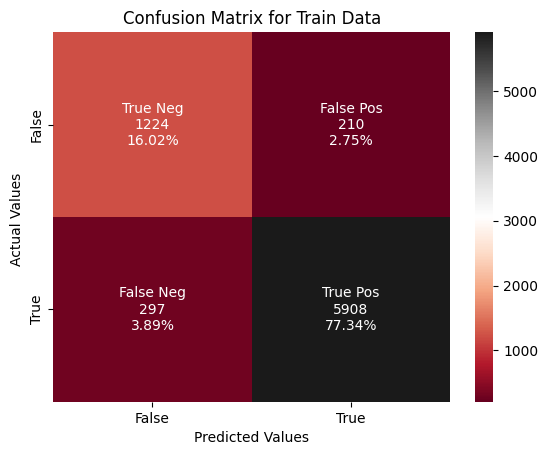

In [85]:
y_pred = xgb_clf.predict(X_train)
cf_matrix = confusion_matrix(y_train, y_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='RdGy')

ax.set_title('Confusion Matrix for Train Data');
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

Confusion Matrix for Testing

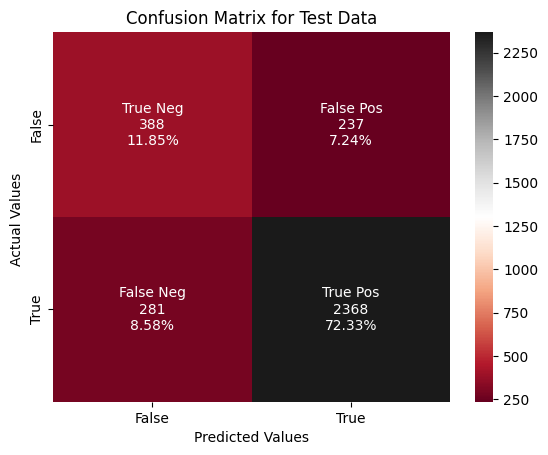

In [86]:
y_pred = xgb_clf.predict(X_test)
cf_matrix = confusion_matrix(y_test, y_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='RdGy')

ax.set_title('Confusion Matrix for Test Data');
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

# Roc Curve 

Roc Curve for Training


In [87]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
#Get predicted probabilites from the model
y_probabilities = xgb_clf.predict_proba(X_train)[:,1]
#Create true and false positive rates
false_positive_rate_xgb_clf,true_positive_rate_xgb_clf,threshold_xgb_clf = roc_curve(y_train,y_probabilities)
#Calculate area under the curve
roc_auc_score(y_train,y_probabilities)

0.9832917508150735

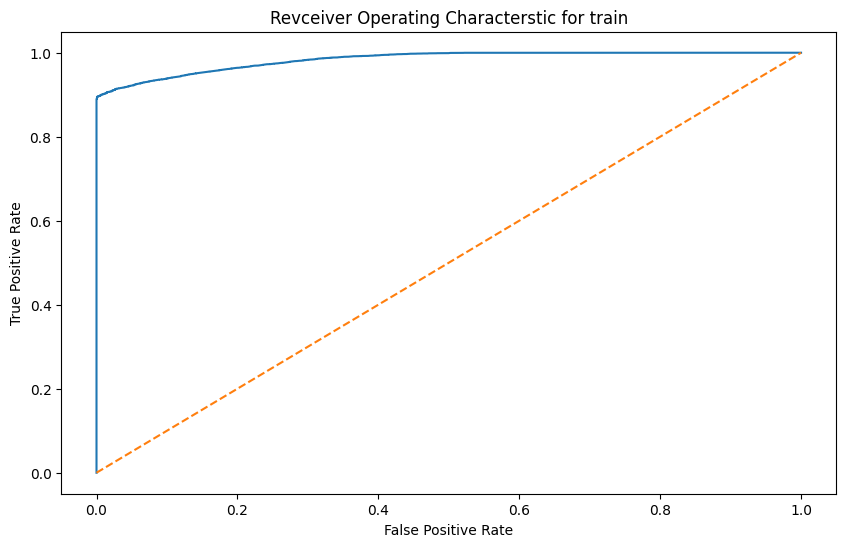

In [88]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(10,6))
plt.title('Revceiver Operating Characterstic for train')
plt.plot(false_positive_rate_xgb_clf,true_positive_rate_xgb_clf)
plt.plot([0,1],ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

Roc Curve for Testing

In [89]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
#Get predicted probabilites from the model
y_probabilities = xgb_clf.predict_proba(X_test)[:,1]
#Create true and false positive rates
false_positive_rate_xgb_clf,true_positive_rate_xgb_clf,threshold_xgb_clf = roc_curve(y_test,y_probabilities)
#Calculate area under the curve
roc_auc_score(y_test,y_probabilities)

0.9332677991694979

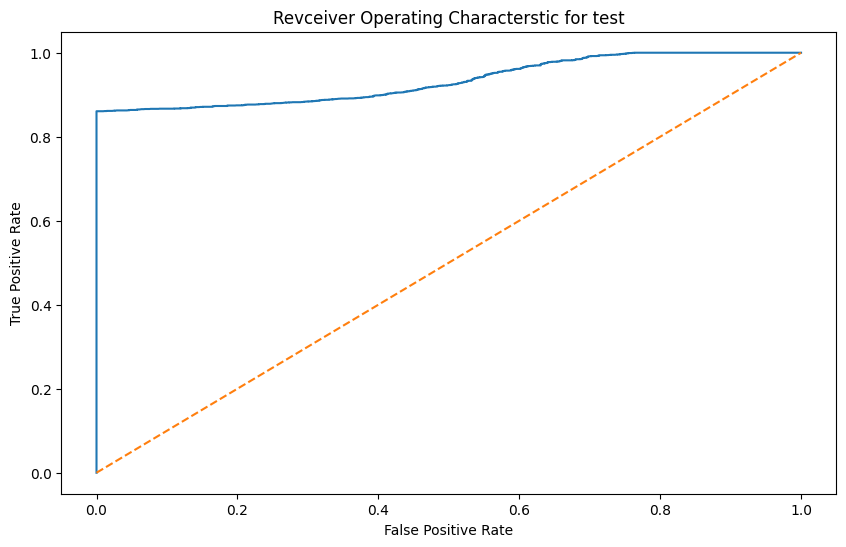

In [90]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(10,6))
plt.title('Revceiver Operating Characterstic for test')
plt.plot(false_positive_rate_xgb_clf,true_positive_rate_xgb_clf)
plt.plot([0,1],ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [91]:
test_score = accuracy_score(y_test, xgb_clf.predict(X_test)) * 100
train_score = accuracy_score(y_train, xgb_clf.predict(X_train)) * 100

results_df = pd.DataFrame(data=[["XGBoost", train_score, test_score]], columns=['Model', 'Training Accuracy %', 'Testing Accuracy %'])
results_df

,Model,Training Accuracy %,Testing Accuracy %
0,XGBoost,93.36,84.18


## 2. Logistic Regression

In [92]:
from sklearn.linear_model import LogisticRegression

lr_clf = LogisticRegression()
lr_clf.fit(X_train, y_train)

print_score(lr_clf, X_train, y_train, X_test, y_test, train=True)
print_score(lr_clf, X_train, y_train, X_test, y_test, train=False)

Train Result:
Accuracy Score: 87.12%
_______________________________________________
CLASSIFICATION REPORT:
                0       1  accuracy  macro avg  weighted avg
precision    0.68    0.91      0.87       0.79          0.87
recall       0.59    0.94      0.87       0.76          0.87
f1-score     0.63    0.92      0.87       0.78          0.87
support   1434.00 6205.00      0.87    7639.00       7639.00
_______________________________________________
Confusion Matrix: 
 [[ 852  582]
 [ 402 5803]]

Test Result:
Accuracy Score: 85.00%
_______________________________________________
CLASSIFICATION REPORT:
               0       1  accuracy  macro avg  weighted avg
precision   0.62    0.90      0.85       0.76          0.84
recall      0.56    0.92      0.85       0.74          0.85
f1-score    0.59    0.91      0.85       0.75          0.85
support   625.00 2649.00      0.85    3274.00       3274.00
_______________________________________________
Confusion Matrix: 
 [[ 349  276]
 [ 

# Confusion Matrix


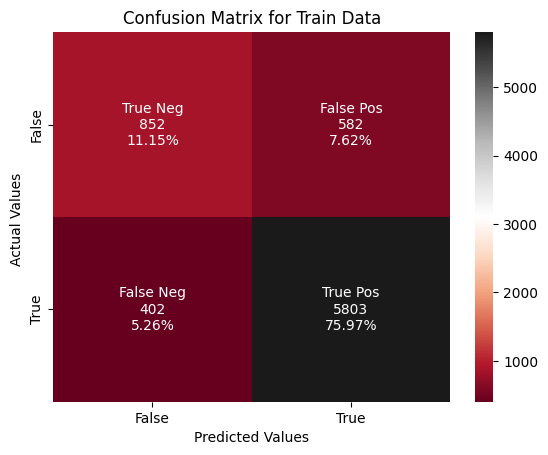

In [93]:
y_pred = lr_clf.predict(X_train)
cf_matrix = confusion_matrix(y_train, y_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='RdGy')

ax.set_title('Confusion Matrix for Train Data');
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

Confusion Matrix for Testing

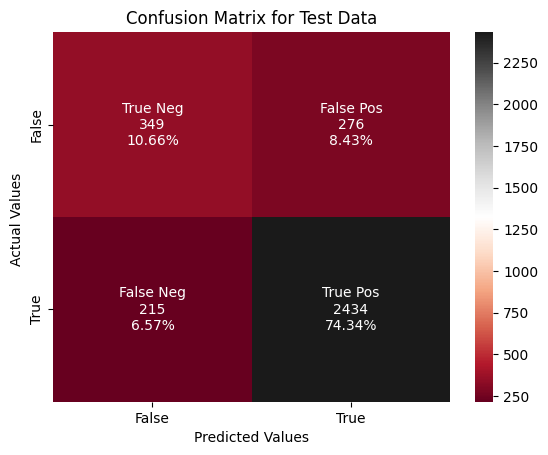

In [94]:
y_pred = lr_clf.predict(X_test)
cf_matrix = confusion_matrix(y_test, y_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='RdGy')

ax.set_title('Confusion Matrix for Test Data');
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

# Roc Curve 

Roc Curve for Training


In [95]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
#Get predicted probabilites from the model
y_probabilities = lr_clf.predict_proba(X_train)[:,1]
#Create true and false positive rates
false_positive_rate_lr_clf,true_positive_rate_lr_clf,threshold_lr_clf = roc_curve(y_train,y_probabilities)
#Calculate area under the curve
roc_auc_score(y_train,y_probabilities)

0.9333888516144693

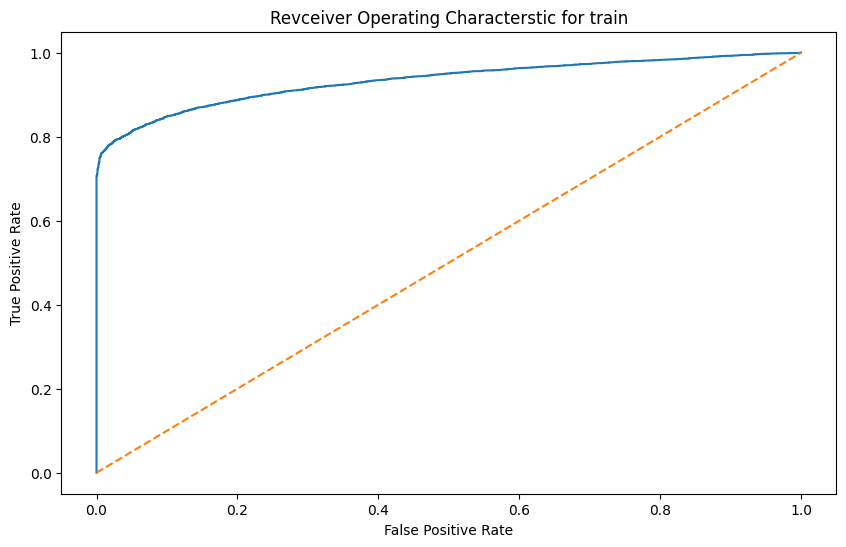

In [96]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(10,6))
plt.title('Revceiver Operating Characterstic for train')
plt.plot(false_positive_rate_lr_clf,true_positive_rate_lr_clf)
plt.plot([0,1],ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

Roc Curve for Testing


In [97]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
#Get predicted probabilites from the model
y_probabilities = lr_clf.predict_proba(X_test)[:,1]
#Create true and false positive rates
false_positive_rate_lr_clf,true_positive_rate_lr_clf,threshold_lr_clf = roc_curve(y_test,y_probabilities)
#Calculate area under the curve
roc_auc_score(y_test,y_probabilities)

0.9179732729331823

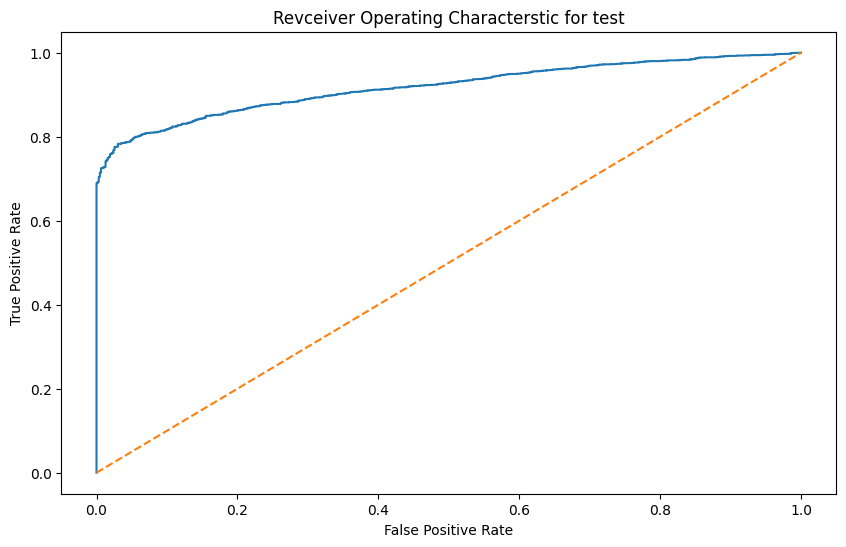

In [98]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(10,6))
plt.title('Revceiver Operating Characterstic for test')
plt.plot(false_positive_rate_lr_clf,true_positive_rate_lr_clf)
plt.plot([0,1],ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [99]:
test_score = accuracy_score(y_test, lr_clf.predict(X_test)) * 100
train_score = accuracy_score(y_train, lr_clf.predict(X_train)) * 100

results_df = pd.DataFrame(data=[["LogisticRegression", train_score, test_score]], columns=['Model', 'Training Accuracy %', 'Testing Accuracy %'])
results_df

,Model,Training Accuracy %,Testing Accuracy %
0,LogisticRegression,87.12,85.00


## 3. K-nearest neighbors

In [100]:
from sklearn.neighbors import KNeighborsClassifier

knn_clf = KNeighborsClassifier(n_neighbors=40, leaf_size=30)
knn_clf.fit(X_train, y_train)

print_score(knn_clf, X_train, y_train, X_test, y_test, train=True)
print_score(knn_clf, X_train, y_train, X_test, y_test, train=False)

Train Result:
Accuracy Score: 89.33%
_______________________________________________
CLASSIFICATION REPORT:
                0       1  accuracy  macro avg  weighted avg
precision    0.69    0.95      0.89       0.82          0.90
recall       0.79    0.92      0.89       0.85          0.89
f1-score     0.74    0.93      0.89       0.83          0.90
support   1434.00 6205.00      0.89    7639.00       7639.00
_______________________________________________
Confusion Matrix: 
 [[1133  301]
 [ 514 5691]]

Test Result:
Accuracy Score: 87.35%
_______________________________________________
CLASSIFICATION REPORT:
               0       1  accuracy  macro avg  weighted avg
precision   0.64    0.94      0.87       0.79          0.88
recall      0.76    0.90      0.87       0.83          0.87
f1-score    0.70    0.92      0.87       0.81          0.88
support   625.00 2649.00      0.87    3274.00       3274.00
_______________________________________________
Confusion Matrix: 
 [[ 476  149]
 [ 

# Confusion Matrix

Confusion Matrix for Training

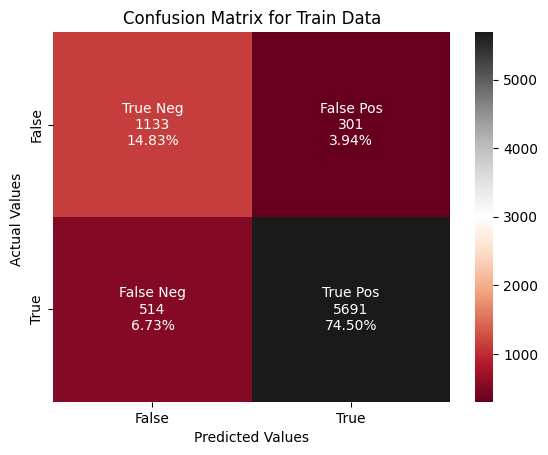

In [101]:
y_pred = knn_clf.predict(X_train)
cf_matrix = confusion_matrix(y_train, y_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='RdGy')

ax.set_title('Confusion Matrix for Train Data');
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

Confusion Matrix for Testing

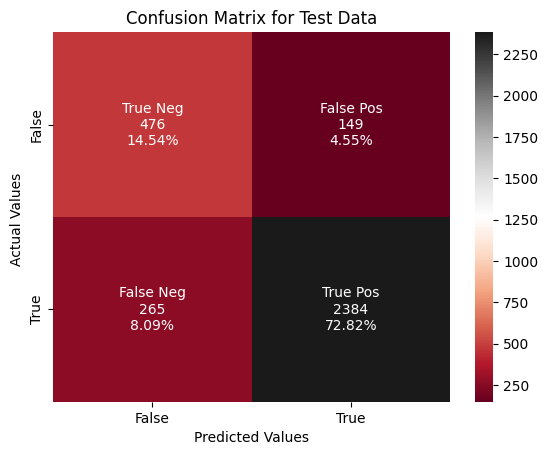

In [102]:
y_pred = knn_clf.predict(X_test)
cf_matrix = confusion_matrix(y_test, y_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='RdGy')

ax.set_title('Confusion Matrix for Test Data');
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

# Roc Curve 

Roc Curve for Training


In [103]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
#Get predicted probabilites from the model
y_probabilities = knn_clf.predict_proba(X_train)[:,1]
#Create true and false positive rates
false_positive_rate_knn_clf,true_positive_rate_knn_clf,threshold_knn_clf = roc_curve(y_train,y_probabilities)
#Calculate area under the curve
roc_auc_score(y_train,y_probabilities)

0.9567972807280761

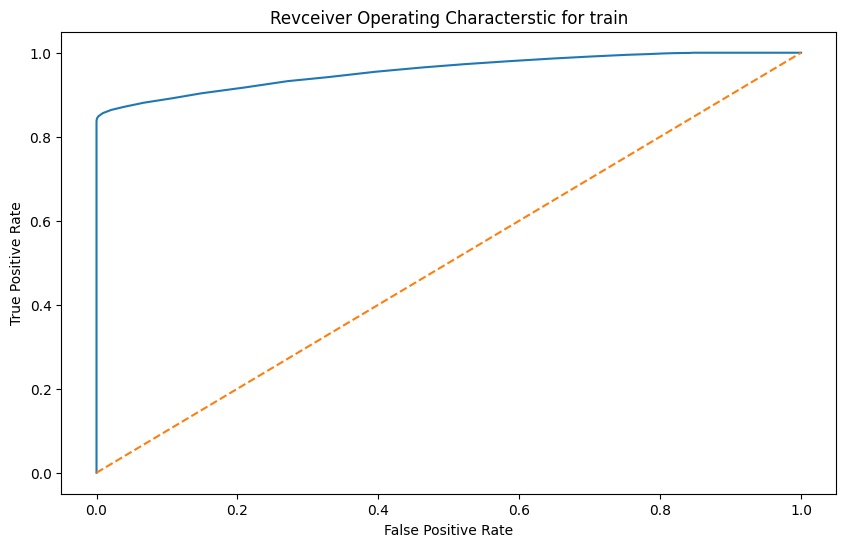

In [104]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(10,6))
plt.title('Revceiver Operating Characterstic for train')
plt.plot(false_positive_rate_knn_clf,true_positive_rate_knn_clf)
plt.plot([0,1],ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

Roc Curve for Testing


In [105]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
#Get predicted probabilites from the model
y_probabilities = knn_clf.predict_proba(X_test)[:,1]
#Create true and false positive rates
false_positive_rate_knn_clf,true_positive_rate_knn_clf,threshold_knn_clf = roc_curve(y_test,y_probabilities)
#Calculate area under the curve
roc_auc_score(y_test,y_probabilities)

0.9431701019252549

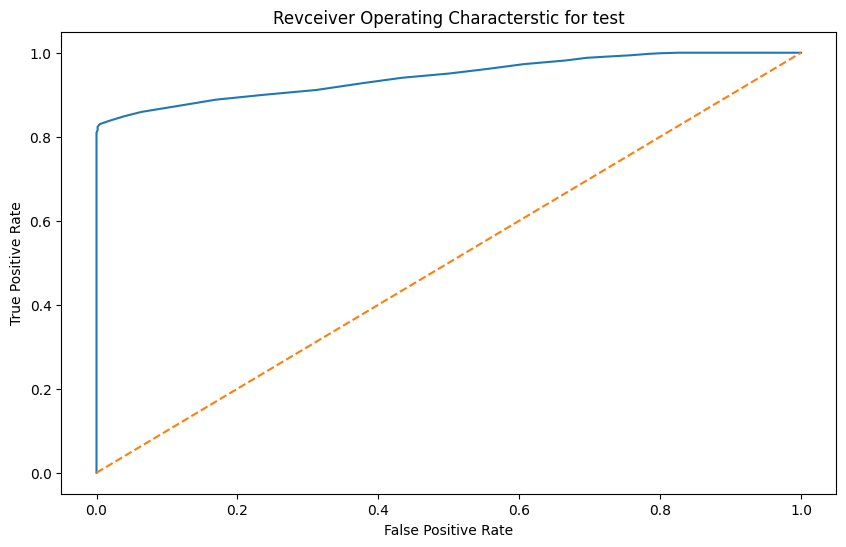

In [106]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(10,6))
plt.title('Revceiver Operating Characterstic for test')
plt.plot(false_positive_rate_knn_clf,true_positive_rate_knn_clf)
plt.plot([0,1],ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

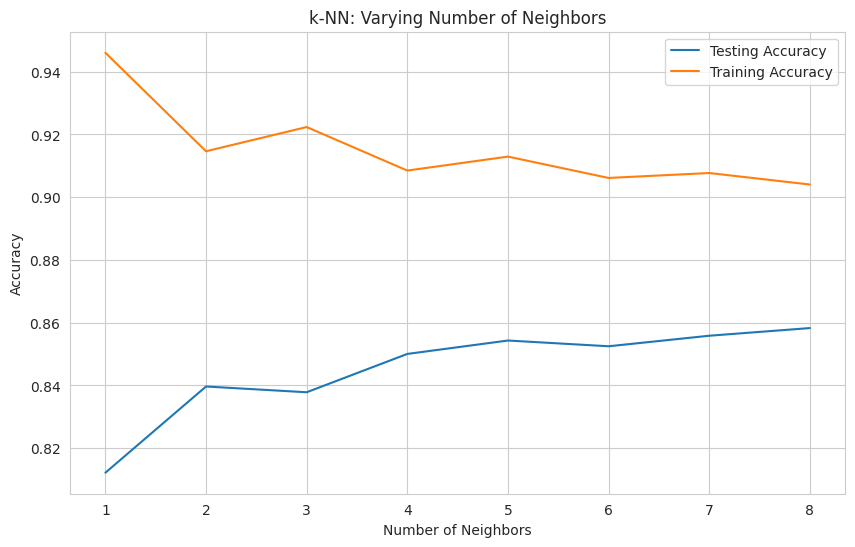

In [107]:
from sklearn.neighbors import KNeighborsClassifier
no_neighbors = np.arange(1, 9)
train_accuracy = np.empty(len(no_neighbors))
test_accuracy = np.empty(len(no_neighbors))

for i, k in enumerate(no_neighbors):
    # We instantiate the classifier
    knn_clf = KNeighborsClassifier(n_neighbors=k)
    # Fit the classifier to the training data
    knn_clf.fit(X_train, y_train)
    
    # Compute accuracy on the training set
    train_accuracy[i] = knn_clf.score(X_train, y_train)

    # Compute accuracy on the testing set
    test_accuracy[i] = knn_clf.score(X_test, y_test)

# Visualization of k values vs accuracy
sns.set_style('whitegrid')
plt.figure(figsize=(10,6))

plt.title('k-NN: Varying Number of Neighbors')
plt.plot(no_neighbors, test_accuracy, label = 'Testing Accuracy')
plt.plot(no_neighbors, train_accuracy, label = 'Training Accuracy')
plt.legend()
plt.xlabel('Number of Neighbors')
plt.ylabel('Accuracy')
plt.show()

In [108]:
test_score = accuracy_score(y_test, knn_clf.predict(X_test)) * 100
train_score = accuracy_score(y_train, knn_clf.predict(X_train)) * 100

results_df= pd.DataFrame(data=[["K-nearest neighbors", train_score, test_score]], 
                          columns=['Model', 'Training Accuracy %', 'Testing Accuracy %'])
results_df

,Model,Training Accuracy %,Testing Accuracy %
0,K-nearest neighbors,90.40,85.83


## 4. Random Forest

In [109]:
from sklearn.ensemble import RandomForestClassifier
rf_clf = RandomForestClassifier(min_samples_split=10, min_samples_leaf=100,)
rf_clf.fit(X_train, y_train)

print_score(rf_clf, X_train, y_train, X_test, y_test, train=True)
print_score(rf_clf, X_train, y_train, X_test, y_test, train=False)

Train Result:
Accuracy Score: 89.61%
_______________________________________________
CLASSIFICATION REPORT:
                0       1  accuracy  macro avg  weighted avg
precision    0.69    0.96      0.90       0.82          0.91
recall       0.82    0.91      0.90       0.87          0.90
f1-score     0.75    0.93      0.90       0.84          0.90
support   1434.00 6205.00      0.90    7639.00       7639.00
_______________________________________________
Confusion Matrix: 
 [[1178  256]
 [ 538 5667]]

Test Result:
Accuracy Score: 87.54%
_______________________________________________
CLASSIFICATION REPORT:
               0       1  accuracy  macro avg  weighted avg
precision   0.64    0.95      0.88       0.79          0.89
recall      0.79    0.89      0.88       0.84          0.88
f1-score    0.71    0.92      0.88       0.81          0.88
support   625.00 2649.00      0.88    3274.00       3274.00
_______________________________________________
Confusion Matrix: 
 [[ 496  129]
 [ 

# Confusion Matrix

Confusion Matrix for Training

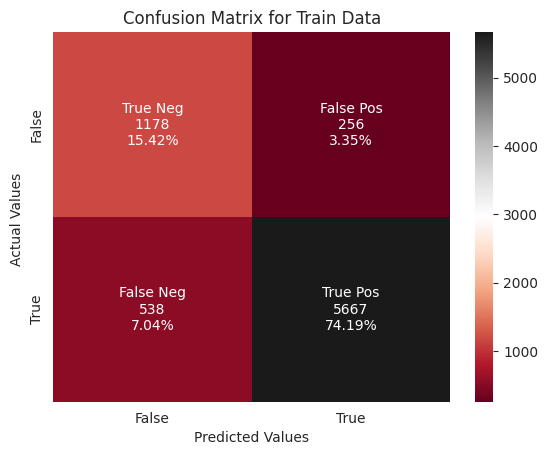

In [110]:
y_pred = rf_clf.predict(X_train)
cf_matrix = confusion_matrix(y_train, y_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='RdGy')

ax.set_title('Confusion Matrix for Train Data');
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

Confusion Matrix for Testing

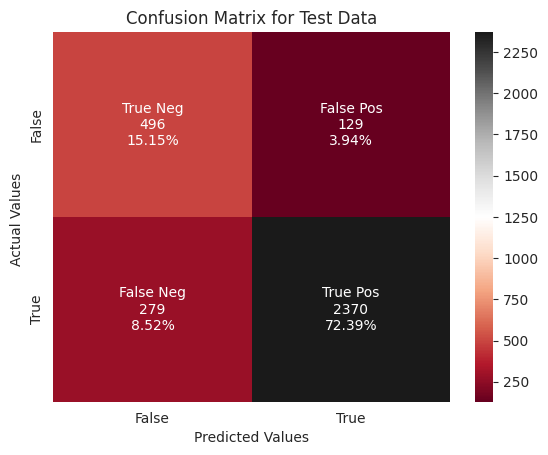

In [111]:
y_pred = rf_clf.predict(X_test)
cf_matrix = confusion_matrix(y_test, y_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='RdGy')

ax.set_title('Confusion Matrix for Test Data');
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

In [112]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
#Get predicted probabilites from the model
y_probabilities = rf_clf.predict_proba(X_train)[:,1]
#Create true and false positive rates
false_positive_rate_rf_clf,true_positive_rate_rf_clf,threshold_rf_clf = roc_curve(y_train,y_probabilities)
#Calculate area under the curve
roc_auc_score(y_train,y_probabilities)

0.9581293261271954

# Roc Curve

Roc Curve for Training

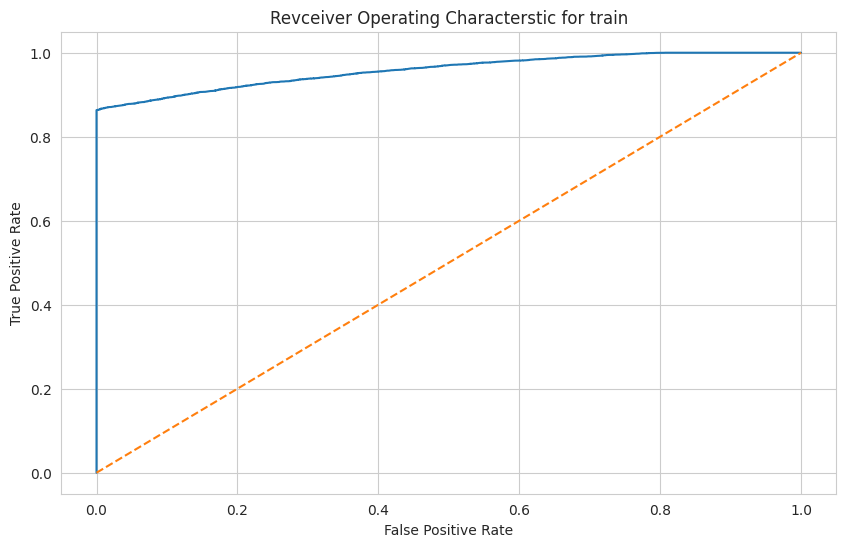

In [113]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(10,6))
plt.title('Revceiver Operating Characterstic for train')
plt.plot(false_positive_rate_rf_clf,true_positive_rate_rf_clf)
plt.plot([0,1],ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

Roc Curve for Testing

In [114]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
#Get predicted probabilites from the model
y_probabilities = rf_clf.predict_proba(X_test)[:,1]
#Create true and false positive rates
false_positive_rate_rf_clf,true_positive_rate_rf_clf,threshold_rf_clf = roc_curve(y_test,y_probabilities)
#Calculate area under the curve
roc_auc_score(y_test,y_probabilities)

0.9463254058135144

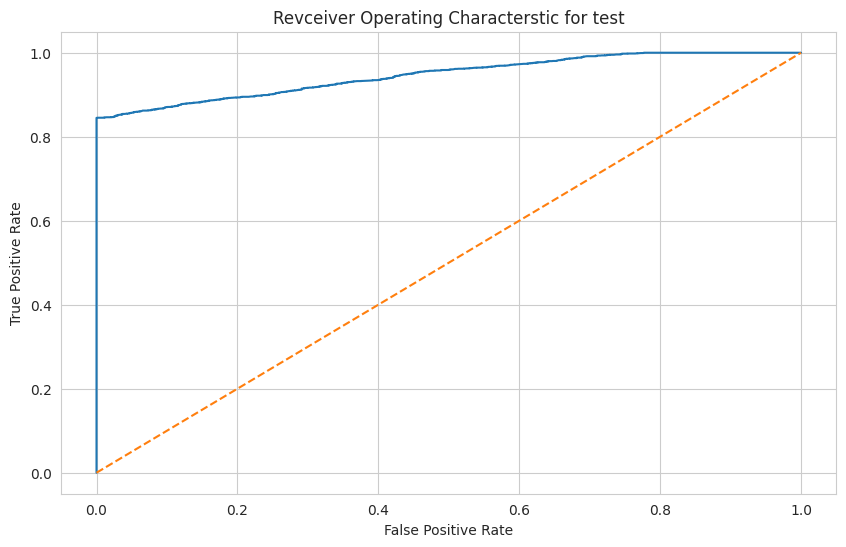

In [115]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(10,6))
plt.title('Revceiver Operating Characterstic for test')
plt.plot(false_positive_rate_rf_clf,true_positive_rate_rf_clf)
plt.plot([0,1],ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [116]:
test_score = accuracy_score(y_test, rf_clf.predict(X_test)) * 100
train_score = accuracy_score(y_train, rf_clf.predict(X_train)) * 100

results_df = pd.DataFrame(data=[["Random Forest Classifier", train_score, test_score]],columns=['Model', 'Training Accuracy %', 'Testing Accuracy %'])
results_df

,Model,Training Accuracy %,Testing Accuracy %
0,Random Forest Classifier,89.61,87.54


## 5. DecisionTreeClassifier


In [117]:
from sklearn.tree import DecisionTreeClassifier
tree_clf = DecisionTreeClassifier(min_samples_split=10, min_samples_leaf=100,)
tree_clf.fit(X_train, y_train)

print_score(tree_clf, X_train, y_train, X_test, y_test, train=True)
print_score(tree_clf, X_train, y_train, X_test, y_test, train=False)

Train Result:
Accuracy Score: 89.66%
_______________________________________________
CLASSIFICATION REPORT:
                0       1  accuracy  macro avg  weighted avg
precision    0.69    0.96      0.90       0.82          0.91
recall       0.82    0.91      0.90       0.87          0.90
f1-score     0.75    0.93      0.90       0.84          0.90
support   1434.00 6205.00      0.90    7639.00       7639.00
_______________________________________________
Confusion Matrix: 
 [[1176  258]
 [ 532 5673]]

Test Result:
Accuracy Score: 87.72%
_______________________________________________
CLASSIFICATION REPORT:
               0       1  accuracy  macro avg  weighted avg
precision   0.64    0.95      0.88       0.80          0.89
recall      0.79    0.90      0.88       0.85          0.88
f1-score    0.71    0.92      0.88       0.82          0.88
support   625.00 2649.00      0.88    3274.00       3274.00
_______________________________________________
Confusion Matrix: 
 [[ 496  129]
 [ 

# Confusion Matrix

Confusion Matrix for Training 

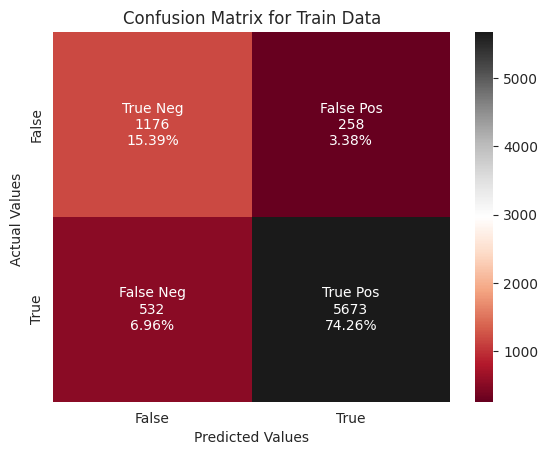

In [118]:
y_pred = tree_clf.predict(X_train)
cf_matrix = confusion_matrix(y_train, y_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='RdGy')

ax.set_title('Confusion Matrix for Train Data');
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

Confusion Matrix for Testing

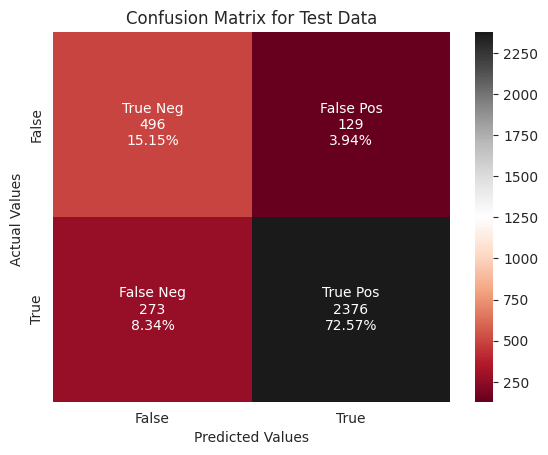

In [119]:
y_pred = tree_clf.predict(X_test)
cf_matrix = confusion_matrix(y_test, y_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='RdGy')

ax.set_title('Confusion Matrix for Test Data');
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

# Roc Curve

Roc Curve for Training

In [120]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
#Get predicted probabilites from the model
y_probabilities = tree_clf.predict_proba(X_train)[:,1]
#Create true and false positive rates
false_positive_rate_tree_clf,true_positive_rate_tree_clf,threshold_tree_clf = roc_curve(y_train,y_probabilities)
#Calculate area under the curve
roc_auc_score(y_train,y_probabilities)

0.9583328556962993

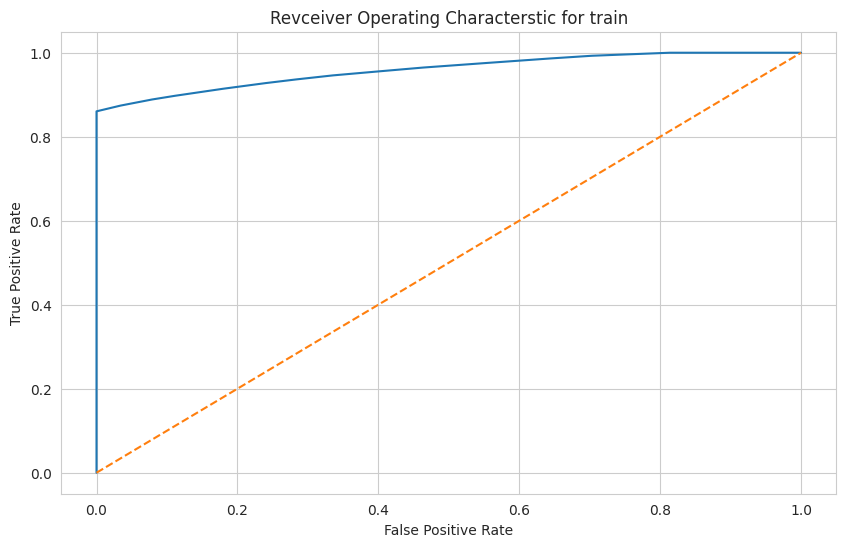

In [121]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(10,6))
plt.title('Revceiver Operating Characterstic for train')
plt.plot(false_positive_rate_tree_clf,true_positive_rate_tree_clf)
plt.plot([0,1],ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

Roc Curve for Testing

In [122]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
#Get predicted probabilites from the model
y_probabilities = tree_clf.predict_proba(X_test)[:,1]
#Create true and false positive rates
false_positive_rate_tree_clf,true_positive_rate_tree_clf,threshold_tree_clf = roc_curve(y_test,y_probabilities)
#Calculate area under the curve
roc_auc_score(y_test,y_probabilities)

0.9462130615326538

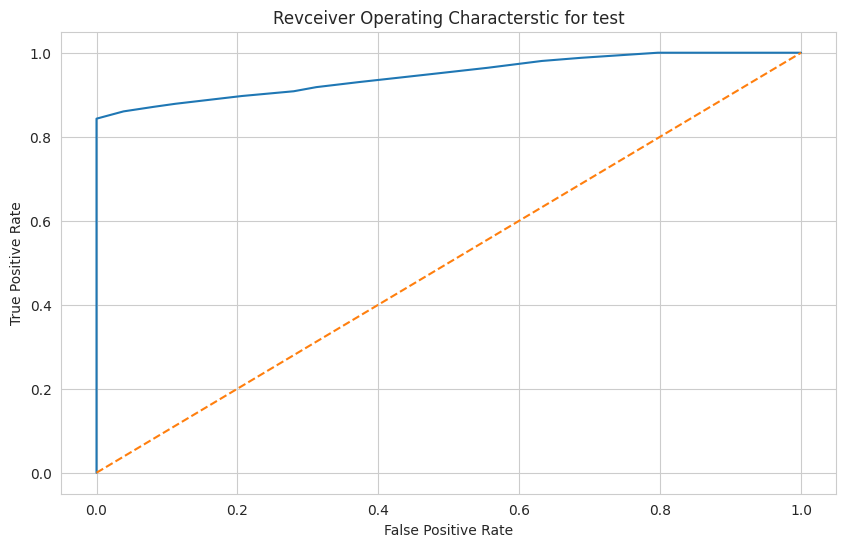

In [123]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(10,6))
plt.title('Revceiver Operating Characterstic for test')
plt.plot(false_positive_rate_tree_clf,true_positive_rate_tree_clf)
plt.plot([0,1],ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [124]:
test_score = accuracy_score(y_test, tree_clf.predict(X_test)) * 100
train_score = accuracy_score(y_train, tree_clf.predict(X_train)) * 100

results_df = pd.DataFrame(data=[["Decision Tree", train_score, test_score]], columns=['Model', 'Training Accuracy %', 'Testing Accuracy %'])
results_df

,Model,Training Accuracy %,Testing Accuracy %
0,Decision Tree,89.66,87.72


## 6. Support Vector machine


In [125]:
from sklearn.svm import SVC

svm_clf = SVC(probability=True, C=5,)
svm_clf.fit(X_train, y_train)

print_score(svm_clf, X_train, y_train, X_test, y_test, train=True)
print_score(svm_clf, X_train, y_train, X_test, y_test, train=False)

Train Result:
Accuracy Score: 89.76%
_______________________________________________
CLASSIFICATION REPORT:
                0       1  accuracy  macro avg  weighted avg
precision    0.69    0.96      0.90       0.82          0.91
recall       0.82    0.92      0.90       0.87          0.90
f1-score     0.75    0.94      0.90       0.84          0.90
support   1434.00 6205.00      0.90    7639.00       7639.00
_______________________________________________
Confusion Matrix: 
 [[1175  259]
 [ 523 5682]]

Test Result:
Accuracy Score: 88.06%
_______________________________________________
CLASSIFICATION REPORT:
               0       1  accuracy  macro avg  weighted avg
precision   0.65    0.95      0.88       0.80          0.89
recall      0.79    0.90      0.88       0.85          0.88
f1-score    0.72    0.92      0.88       0.82          0.88
support   625.00 2649.00      0.88    3274.00       3274.00
_______________________________________________
Confusion Matrix: 
 [[ 495  130]
 [ 

# Confusion Matrix

Confusion Matrix for Training


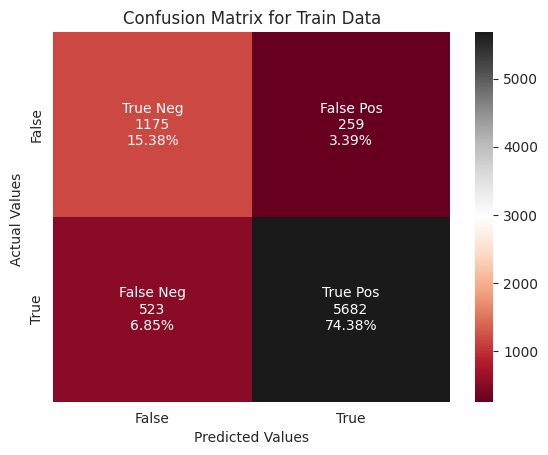

In [126]:
y_pred = svm_clf.predict(X_train)
cf_matrix = confusion_matrix(y_train, y_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='RdGy')

ax.set_title('Confusion Matrix for Train Data');
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

Confusion Matrix for Testing

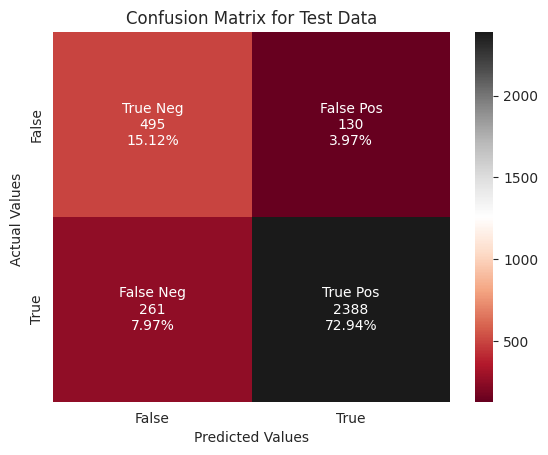

In [127]:
y_pred = svm_clf.predict(X_test)
cf_matrix = confusion_matrix(y_test, y_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='RdGy')

ax.set_title('Confusion Matrix for Test Data');
ax.set_xlabel('Predicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

# Roc Curve


Roc Curve for Training

In [128]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
#Get predicted probabilites from the model
y_probabilities = svm_clf.predict_proba(X_train)[:,1]
#Create true and false positive rates
false_positive_rate_svm_clf,true_positive_rate_svm_clf,threshold_svm_clf = roc_curve(y_train,y_probabilities)
#Calculate area under the curve
roc_auc_score(y_train,y_probabilities)

0.9555352512988917

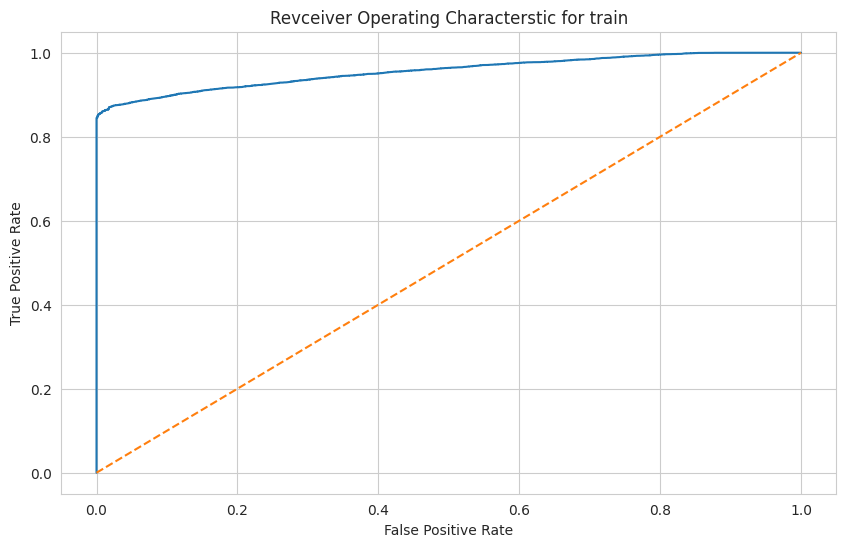

In [129]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(10,6))
plt.title('Revceiver Operating Characterstic for train')
plt.plot(false_positive_rate_svm_clf,true_positive_rate_svm_clf)
plt.plot([0,1],ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

Roc Curve for Testing

In [130]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
#Get predicted probabilites from the model
y_probabilities = svm_clf.predict_proba(X_test)[:,1]
#Create true and false positive rates
false_positive_rate_svm_clf,true_positive_rate_svm_clf,threshold_svm_clf = roc_curve(y_test,y_probabilities)
#Calculate area under the curve
roc_auc_score(y_test,y_probabilities)

0.9464664401661003

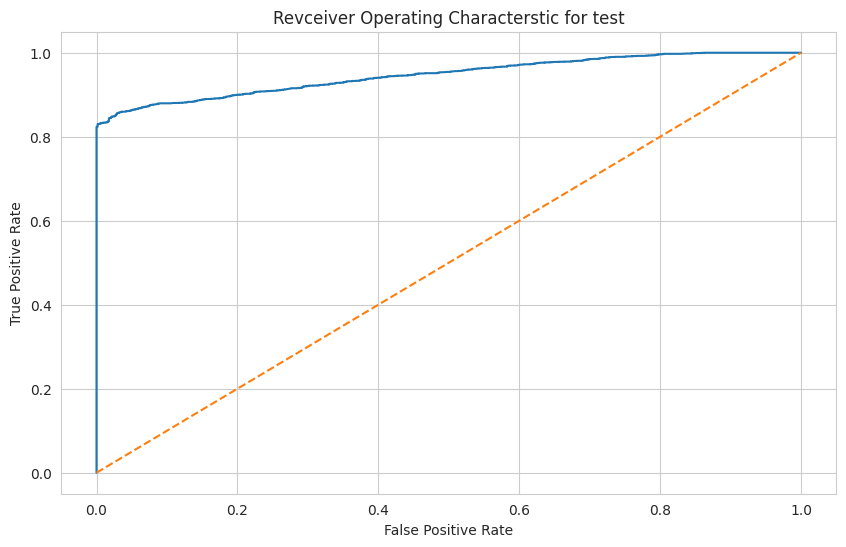

In [131]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(10,6))
plt.title('Revceiver Operating Characterstic for test')
plt.plot(false_positive_rate_svm_clf,true_positive_rate_svm_clf)
plt.plot([0,1],ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [132]:
test_score = accuracy_score(y_test, svm_clf.predict(X_test)) * 100
train_score = accuracy_score(y_train, svm_clf.predict(X_train)) * 100

results_df = pd.DataFrame(data=[["Support Vector Machine", train_score, test_score]], columns=['Model', 'Training Accuracy %', 'Testing Accuracy %'])
results_df

,Model,Training Accuracy %,Testing Accuracy %
0,Support Vector Machine,89.76,88.06


# **Comparing ROC Curve of k-Nearest Neighbors, Logistic Regression, XGB00st classifier, Random Forest Classifier, Support Vector Machine and Decision Tree**

In [133]:
from sklearn.metrics import auc

auc_xgb=auc(false_positive_rate_xgb_clf,true_positive_rate_xgb_clf)
auc_lr=auc(false_positive_rate_lr_clf,true_positive_rate_lr_clf)
auc_knn=auc(false_positive_rate_knn_clf,true_positive_rate_knn_clf)
auc_rf=auc(false_positive_rate_rf_clf,true_positive_rate_rf_clf)
auc_tree=auc(false_positive_rate_tree_clf,true_positive_rate_tree_clf)
auc_svm=auc(false_positive_rate_svm_clf,true_positive_rate_svm_clf)

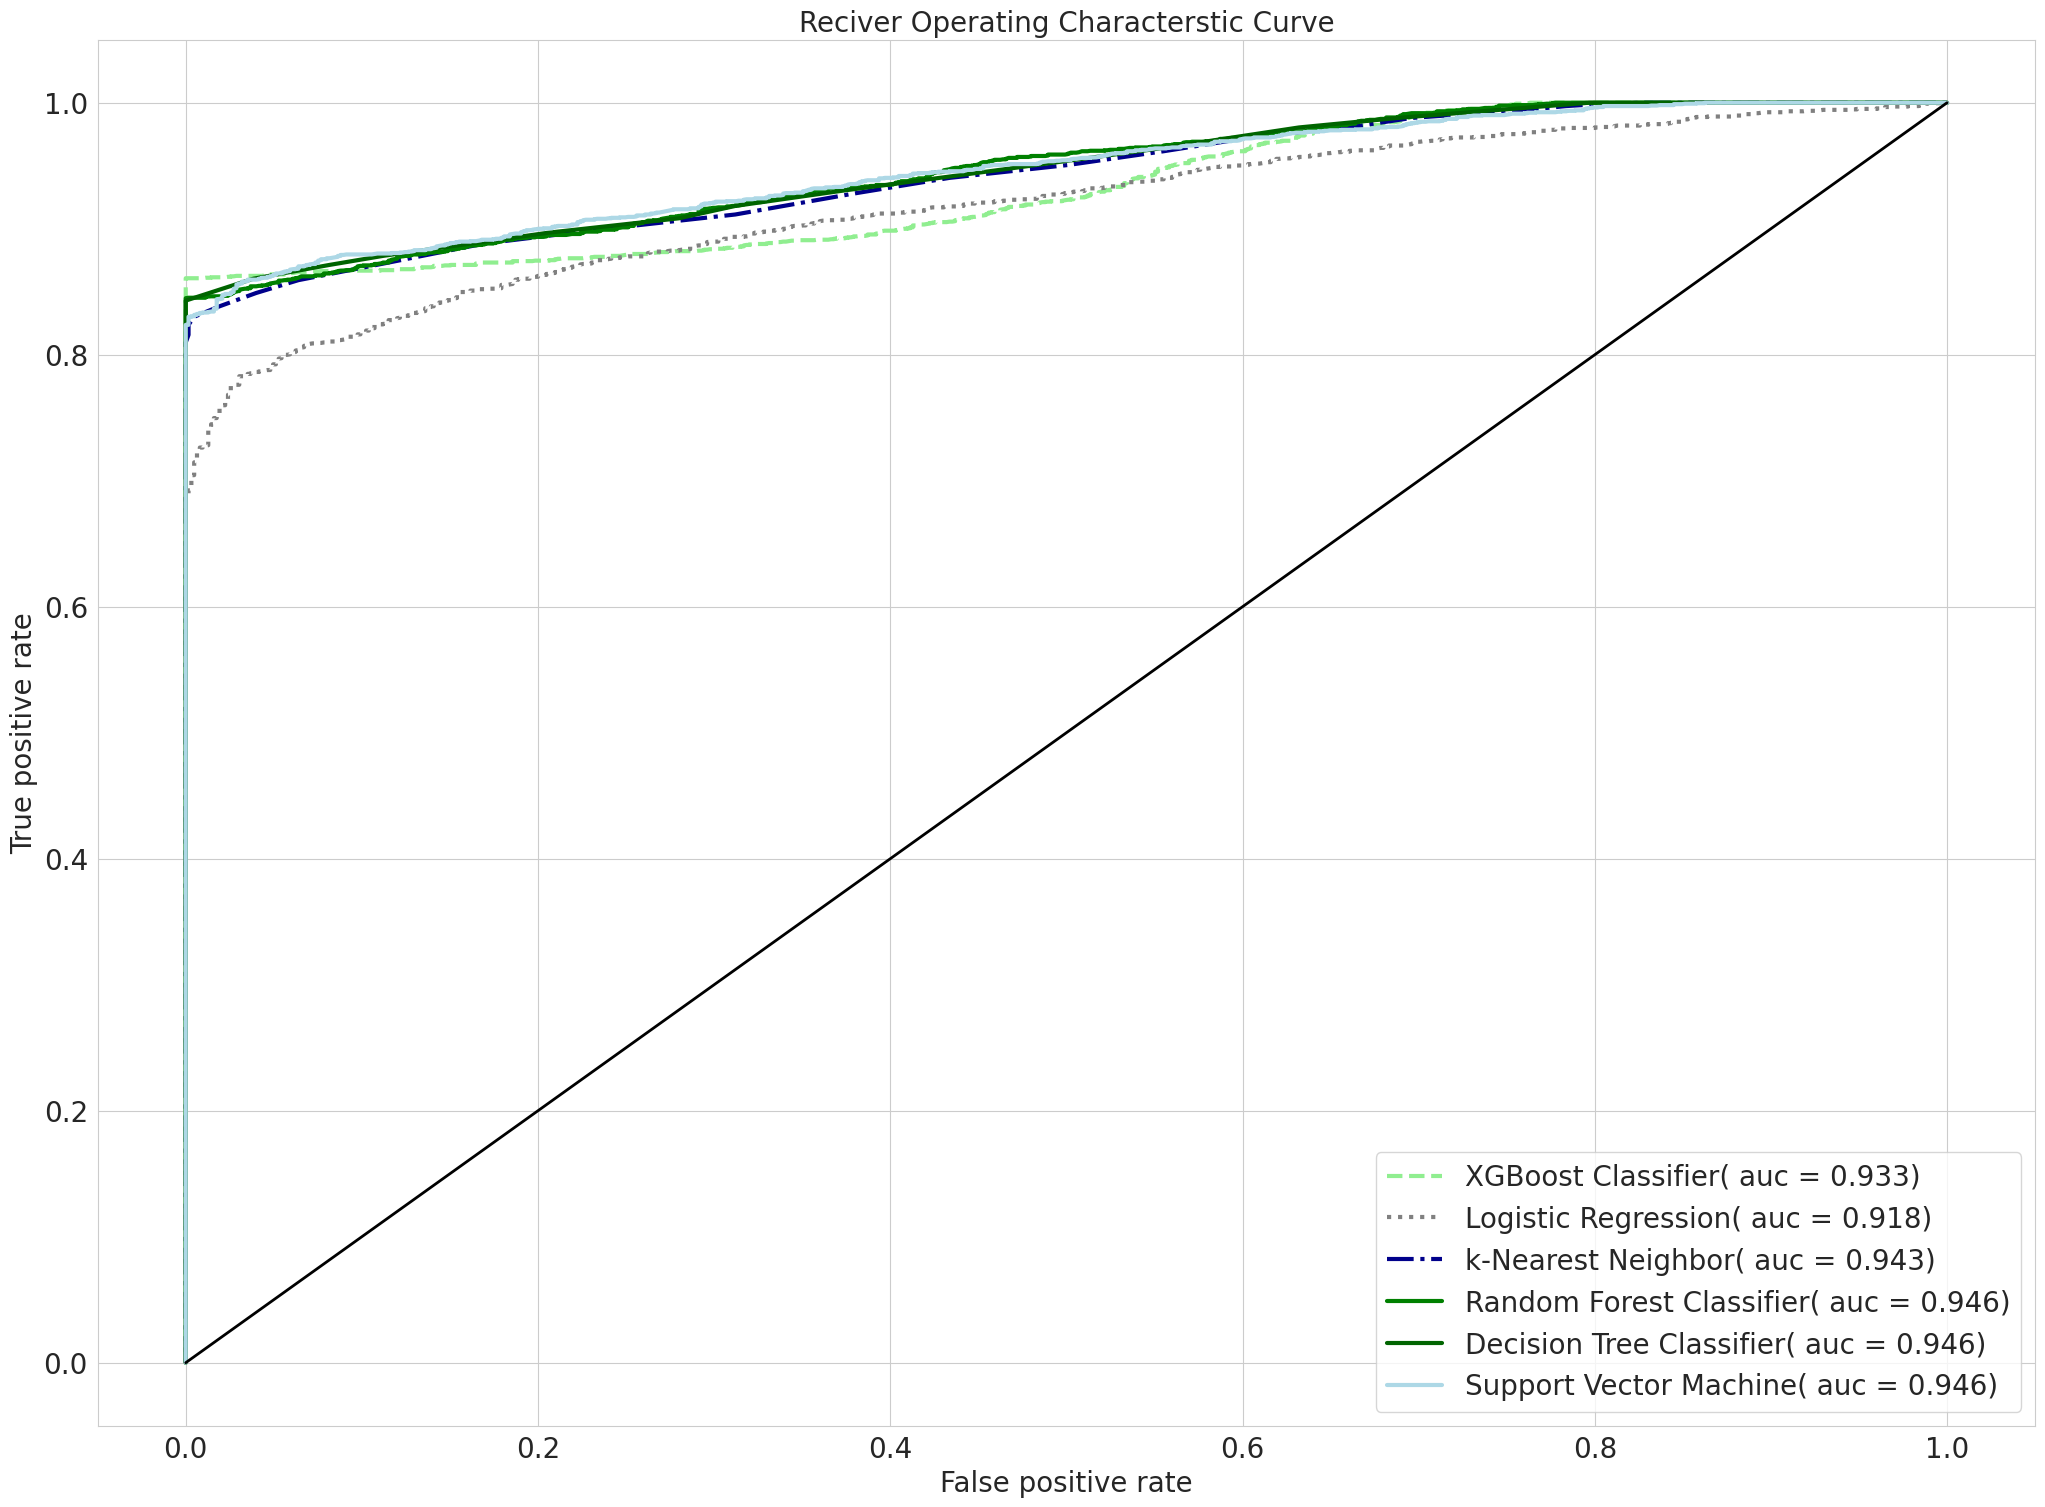

In [134]:
#Plot All ROC Curve`s

sns.set_style('whitegrid')
plt.figure(figsize=(25,18))
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.title('Reciver Operating Characterstic Curve',fontsize=20)

plt.plot(false_positive_rate_xgb_clf,true_positive_rate_xgb_clf,linewidth=3,color="lightgreen",linestyle='--',label='XGBoost Classifier( auc = %0.3f)' % auc_xgb)
plt.plot(false_positive_rate_lr_clf,true_positive_rate_lr_clf,linewidth=3,color="gray",linestyle='dotted',label='Logistic Regression( auc = %0.3f)' % auc_lr)
plt.plot(false_positive_rate_knn_clf,true_positive_rate_knn_clf,linewidth=3,color="darkblue",linestyle='-.',label='k-Nearest Neighbor( auc = %0.3f)' % auc_knn)
plt.plot(false_positive_rate_rf_clf,true_positive_rate_rf_clf,linewidth=3,color="green",linestyle='solid',label='Random Forest Classifier( auc = %0.3f)' % auc_rf)
plt.plot(false_positive_rate_tree_clf,true_positive_rate_tree_clf,linewidth=3,color="darkgreen",linestyle='-',label='Decision Tree Classifier( auc = %0.3f)' % auc_tree)
plt.plot(false_positive_rate_svm_clf,true_positive_rate_svm_clf,linewidth=3,color="lightblue",linestyle='solid',label='Support Vector Machine( auc = %0.3f)' % auc_svm)

plt.plot([0,1],linewidth=2,color="black",linestyle='-')
#plt.plot([0,0],[1,0],c='.1')
#plt.plot([1,1],c='.1')
plt.ylabel('True positive rate',fontsize=20)
plt.xlabel('False positive rate',fontsize=20)
plt.legend(fontsize=20)
plt.show()